# Setup

## Load packages

In [1]:
# Load up necessary packages. 
import os
import glob
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# Import my custom utils.
import utils
importlib.reload(utils)

<module 'utils' from '/tscc/projects/ps-yeolab3/kflanagan/plip_plop/V2_feature_vectors/utils.py'>

## Load results

In [2]:
INPUT_DIR = "/tscc/lustre/ddn/scratch/kflanagan/plip_plop_results/fv_processed_inputs/"

comparison_table = pd.read_csv("/tscc/nfs/home/kflanagan/projects/plip_plop/V2_feature_vectors/select_comparisons/encode_initial_30_comparisons.tsv", sep="\t")

In [3]:
comparison_table = comparison_table.loc[3:4]
###!!!### PRPF4 and PRPF8 are an interesting case, seems to be common to have a roughly 40 nucleotide shift. 

In [4]:
comparison_table

,category,experiment_A,experiment_B,window_A,plus_1_A,plus_2_A,minus_1_A,minus_2_A,plus_IN_1_A,minus_IN_1_A,...,window_B,plus_1_B,plus_2_B,minus_1_B,minus_2_B,plus_IN_1_B,minus_IN_1_B,bam_1_B,bam_2_B,bam_IN_1_B
3,similar,TIA1_HepG2_ENCSR623VEQ,TIAL1_HepG2_ENCSR322HHA,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...
4,similar,SAFB_K562_ENCSR484LAB,SAFB2_K562_ENCSR943MHU,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...,/tscc/projects/ps-yeolab5/rbp-portal/encode3/e...


# Organize data

In [5]:
comparison_data = {}
all_metadata = []

for comparison_id, row in comparison_table.iterrows():
    experiment_A = row["experiment_A"]
    experiment_B = row["experiment_B"]
    npz_file = os.path.join(INPUT_DIR, f"{experiment_A}_{experiment_B}.npz")

    if not os.path.exists(npz_file):
        print(f"Missing: {npz_file}")
        continue

    with np.load(npz_file) as data:
        ip_A = data["ip_signals_A"].astype(np.float32)
        in_A = data["in_signals_A"].astype(np.float32)
        ip_B = data["ip_signals_B"].astype(np.float32)
        in_B = data["in_signals_B"].astype(np.float32)

        ip_A_library_sizes = data["ip_A_library_sizes"]
        in_A_library_sizes = data["in_A_library_sizes"]
        ip_B_library_sizes = data["ip_B_library_sizes"]
        in_B_library_sizes = data["in_B_library_sizes"]

        n_windows = len(ip_A)

        if not (len(ip_A) == len(in_A) == len(ip_B) == len(in_B)):
            raise ValueError(f"Signal arrays do not match for comparison {comparison_id}.")
        if in_A.shape[1] != 1 or in_B.shape[1] != 1:
            raise ValueError(f"Expected one IN replicate for comparison {comparison_id}.")

        # Convert raw coverage to RPM.
        ip_A_rpm = ip_A * (1e6 / ip_A_library_sizes[None, :, None])
        in_A_rpm = in_A * (1e6 / in_A_library_sizes[None, :, None])
        ip_B_rpm = ip_B * (1e6 / ip_B_library_sizes[None, :, None])
        in_B_rpm = in_B * (1e6 / in_B_library_sizes[None, :, None])

        # RPM corresponding approximately to one read.
        ip_A_pc = utils.calculate_rpm_pseudocount(ip_A_library_sizes)
        in_A_pc = utils.calculate_rpm_pseudocount(in_A_library_sizes)
        ip_B_pc = utils.calculate_rpm_pseudocount(ip_B_library_sizes)
        in_B_pc = utils.calculate_rpm_pseudocount(in_B_library_sizes)

        # Abundance-weighted IP/IN enrichment using the central 300-nt core
        # to define the shared A+B abundance reference.
        signal_A = np.empty_like(ip_A_rpm)
        signal_B = np.empty_like(ip_B_rpm)
        
        for w in range(n_windows):
            mean_A = ip_A_rpm[w, :, 150:450].mean()
            mean_B = ip_B_rpm[w, :, 150:450].mean()
            mean_AB = (mean_A + mean_B) / 2
        
            for r in range(ip_A.shape[1]):
                signal_A[w, r] = utils.abundance_weighted_enrichment(
                    ip_A_rpm[w, r], in_A_rpm[w, 0], ip_A_pc, in_A_pc, mean_AB
                )
            for r in range(ip_B.shape[1]):
                signal_B[w, r] = utils.abundance_weighted_enrichment(
                    ip_B_rpm[w, r], in_B_rpm[w, 0], ip_B_pc, in_B_pc, mean_AB
                )

        comparison_data[comparison_id] = {
            "signal_A": signal_A,
            "signal_B": signal_B,
            "ip_A_rpm": ip_A_rpm,
            "in_A_rpm": in_A_rpm,
            "ip_B_rpm": ip_B_rpm,
            "in_B_rpm": in_B_rpm
        }

        metadata = pd.DataFrame({
            "comparison_id": comparison_id,
            "window_idx": np.arange(n_windows),
            "category": row["category"],
            "experiment_A": experiment_A,
            "experiment_B": experiment_B,
            "chrom": data["chrom"],
            "start": data["start"],
            "end": data["end"],
            "strand": data["strand"],
            "region_id": data["region_id"],
            "block_number": data["block_number"],
            "context_start": data["context_start"],
            "context_end": data["context_end"],
        })

        all_metadata.append(metadata)

metadata = pd.concat(all_metadata, ignore_index=True)

print("Comparisons loaded:", len(comparison_data))
print("Total windows:", len(metadata))

Comparisons loaded: 2
Total windows: 55695


# C17 method

In [6]:
for comparison_id, comp in comparison_data.items():
    comp["c17"], comp["c17_lags"] = utils.C17(
        comp["signal_A"],
        comp["signal_B"],
        max_lag=150
    )

    print(
        comparison_id,
        comp["c17"].shape,
        "NaN:",
        np.isnan(comp["c17"]).sum()
    )

3 (14197, 2, 2, 301) NaN: 0
4 (41498, 2, 2, 301) NaN: 0


In [7]:
metadata["c17_max"] = np.nan
metadata["c17_best_lag"] = np.nan
metadata["c17_zero"] = np.nan
metadata["c17_gain"] = np.nan

for comparison_id, comp in comparison_data.items():
    xcorr = comp["c17"]
    lags = comp["c17_lags"]

    with np.errstate(invalid="ignore"):
        mean_curve = np.nanmean(xcorr, axis=(1, 2))

    valid = np.any(~np.isnan(mean_curve), axis=1)
    max_corr = np.full(len(mean_curve), np.nan)
    best_lag = np.full(len(mean_curve), np.nan)

    max_corr[valid] = np.nanmax(mean_curve[valid], axis=1)
    
    for i in np.where(valid)[0]:
        tied = np.where(np.isclose(mean_curve[i], max_corr[i], equal_nan=False))[0]
        best_idx = tied[np.argmin(np.abs(lags[tied]))]
        best_lag[i] = lags[best_idx]

    zero_idx = np.where(lags == 0)[0][0]
    zero_corr = mean_curve[:, zero_idx]
    gain = max_corr - zero_corr

    comp["c17_mean_curve"] = mean_curve

    mask = metadata["comparison_id"] == comparison_id
    order = metadata.loc[mask, "window_idx"].to_numpy()

    metadata.loc[mask, "c17_max"] = max_corr[order]
    metadata.loc[mask, "c17_best_lag"] = best_lag[order]
    metadata.loc[mask, "c17_zero"] = zero_corr[order]
    metadata.loc[mask, "c17_gain"] = gain[order]

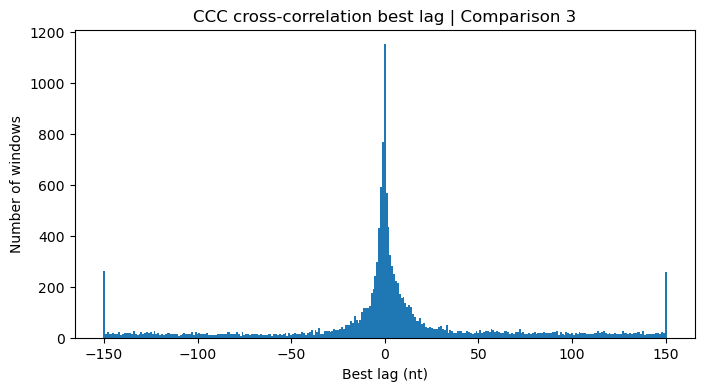

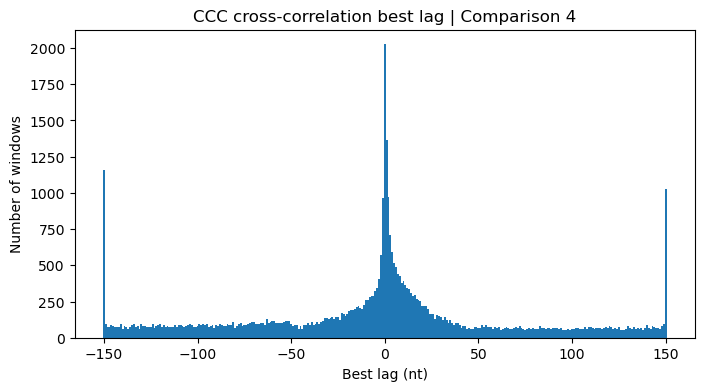

In [8]:
for comparison_id, group in metadata.groupby("comparison_id"):
    plt.figure(figsize=(8, 4))
    plt.hist(
        group["c17_best_lag"].dropna(),
        bins=np.arange(-150.5, 151.5, 1)
    )

    plt.xlabel("Best lag (nt)")
    plt.ylabel("Number of windows")
    plt.title(f"CCC cross-correlation best lag | Comparison {comparison_id}")
    plt.show()

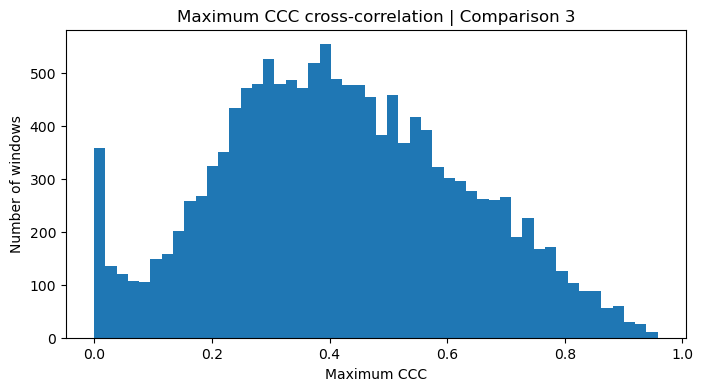

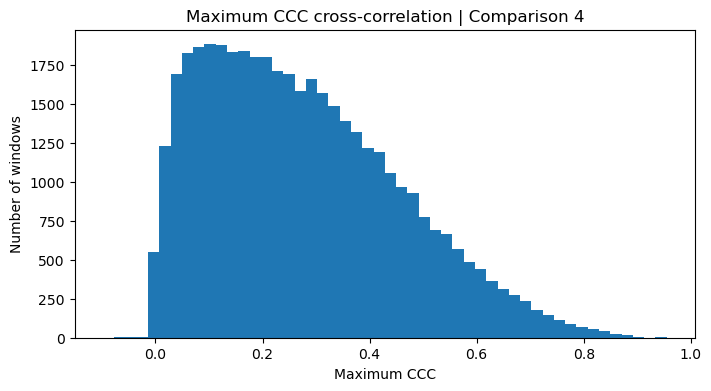

In [9]:
for comparison_id, group in metadata.groupby("comparison_id"):
    plt.figure(figsize=(8, 4))
    plt.hist(group["c17_max"].dropna(), bins=50)

    plt.xlabel("Maximum CCC")
    plt.ylabel("Number of windows")
    plt.title(f"Maximum CCC cross-correlation | Comparison {comparison_id}")
    plt.show()

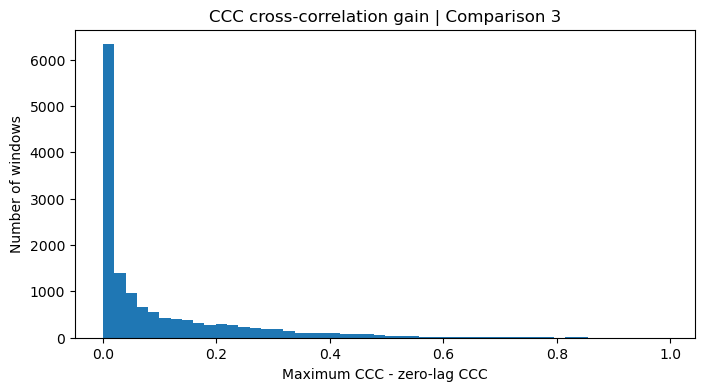

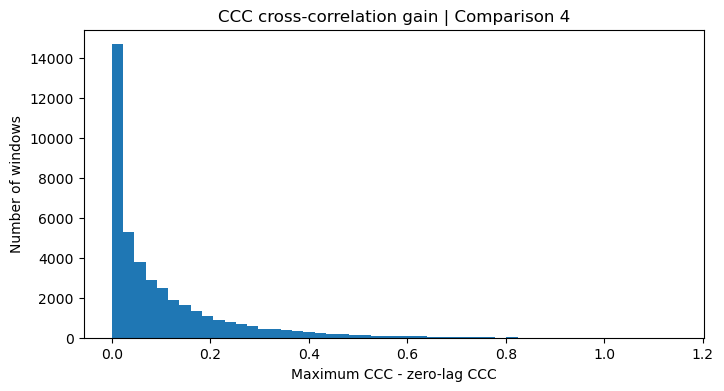

In [10]:
for comparison_id, group in metadata.groupby("comparison_id"):
    plt.figure(figsize=(8, 4))
    plt.hist(group["c17_gain"].dropna(), bins=50)

    plt.xlabel("Maximum CCC - zero-lag CCC")
    plt.ylabel("Number of windows")
    plt.title(f"CCC cross-correlation gain | Comparison {comparison_id}")
    plt.show()

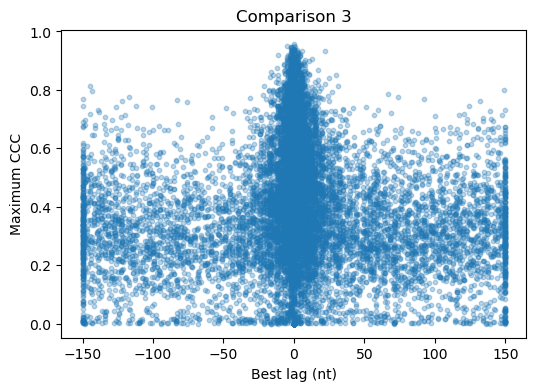

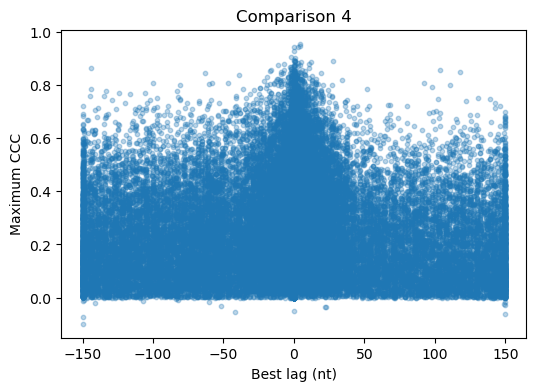

In [11]:
for comparison_id, group in metadata.groupby("comparison_id"):
    plt.figure(figsize=(6, 4))
    plt.scatter(
        group["c17_best_lag"],
        group["c17_max"],
        alpha=0.3,
        s=10
    )

    plt.xlabel("Best lag (nt)")
    plt.ylabel("Maximum CCC")
    plt.title(f"Comparison {comparison_id}")
    plt.show()

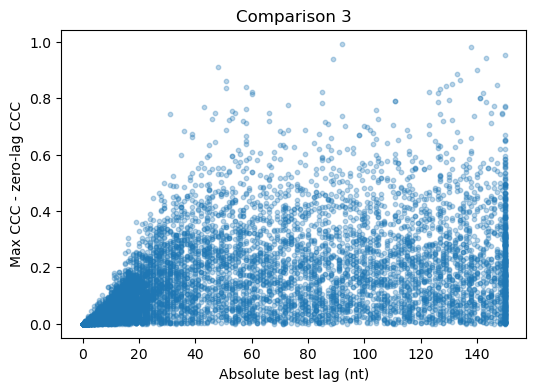

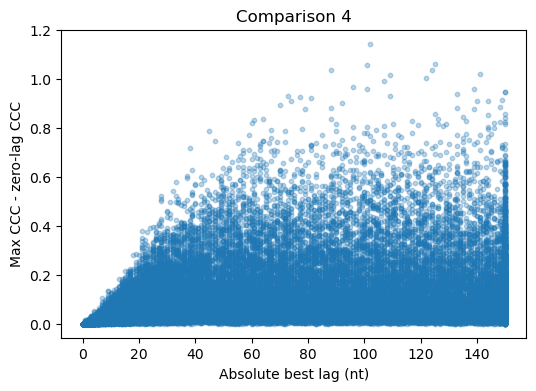

In [12]:
for comparison_id, group in metadata.groupby("comparison_id"):
    plt.figure(figsize=(6, 4))
    plt.scatter(
        np.abs(group["c17_best_lag"]),
        group["c17_gain"],
        alpha=0.3,
        s=10
    )

    plt.xlabel("Absolute best lag (nt)")
    plt.ylabel("Max CCC - zero-lag CCC")
    plt.title(f"Comparison {comparison_id}")
    plt.show()

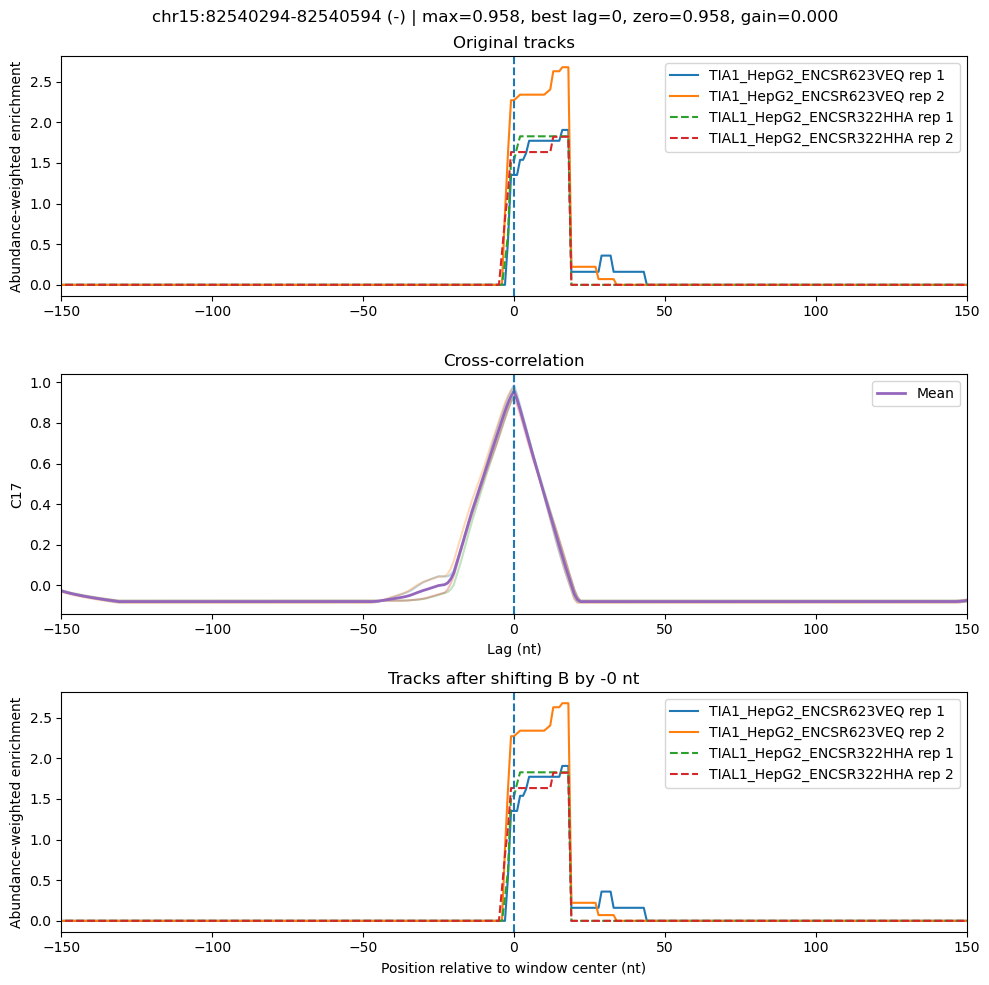

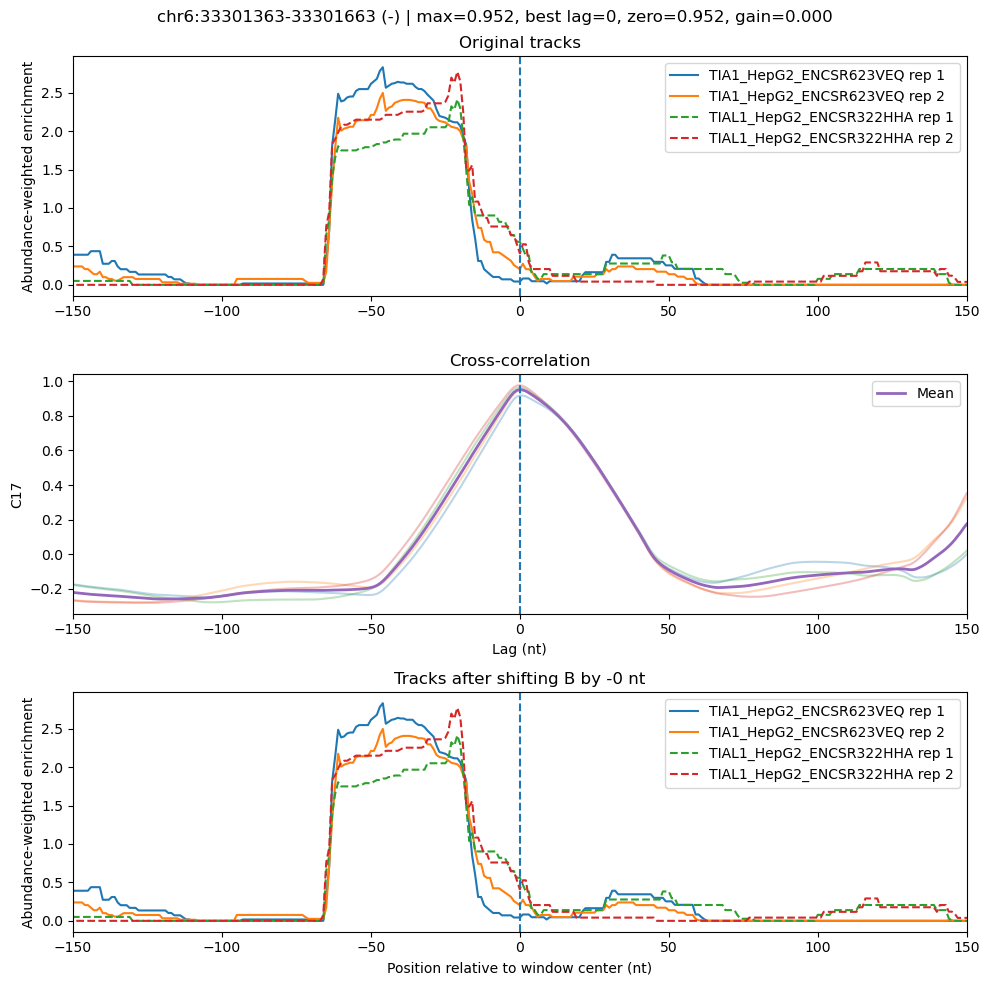

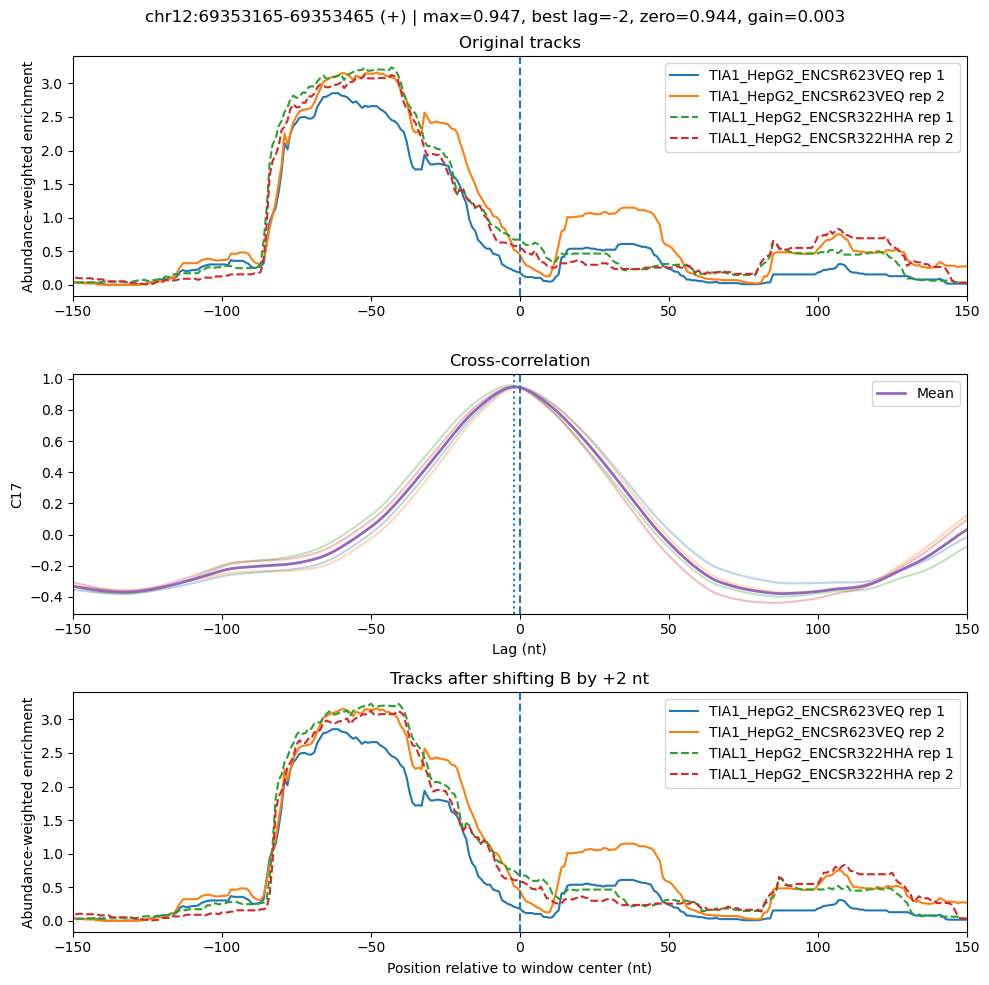

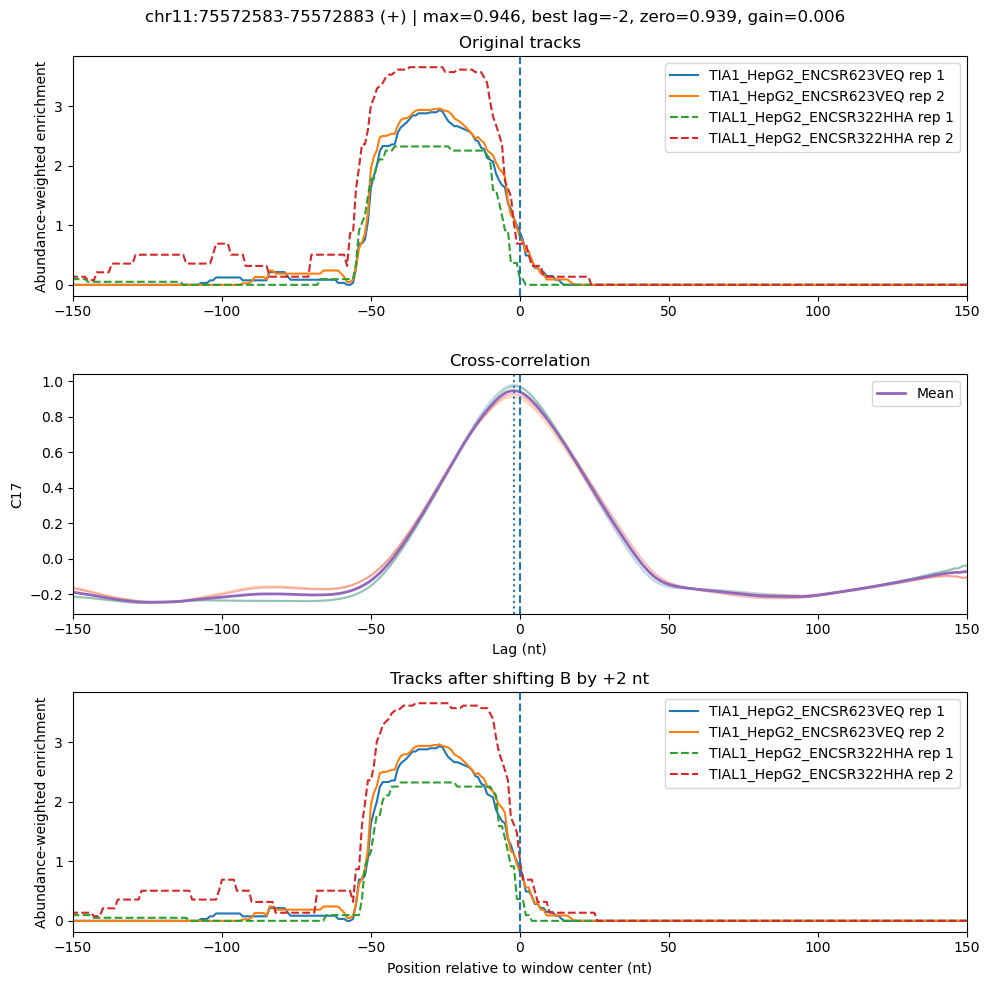

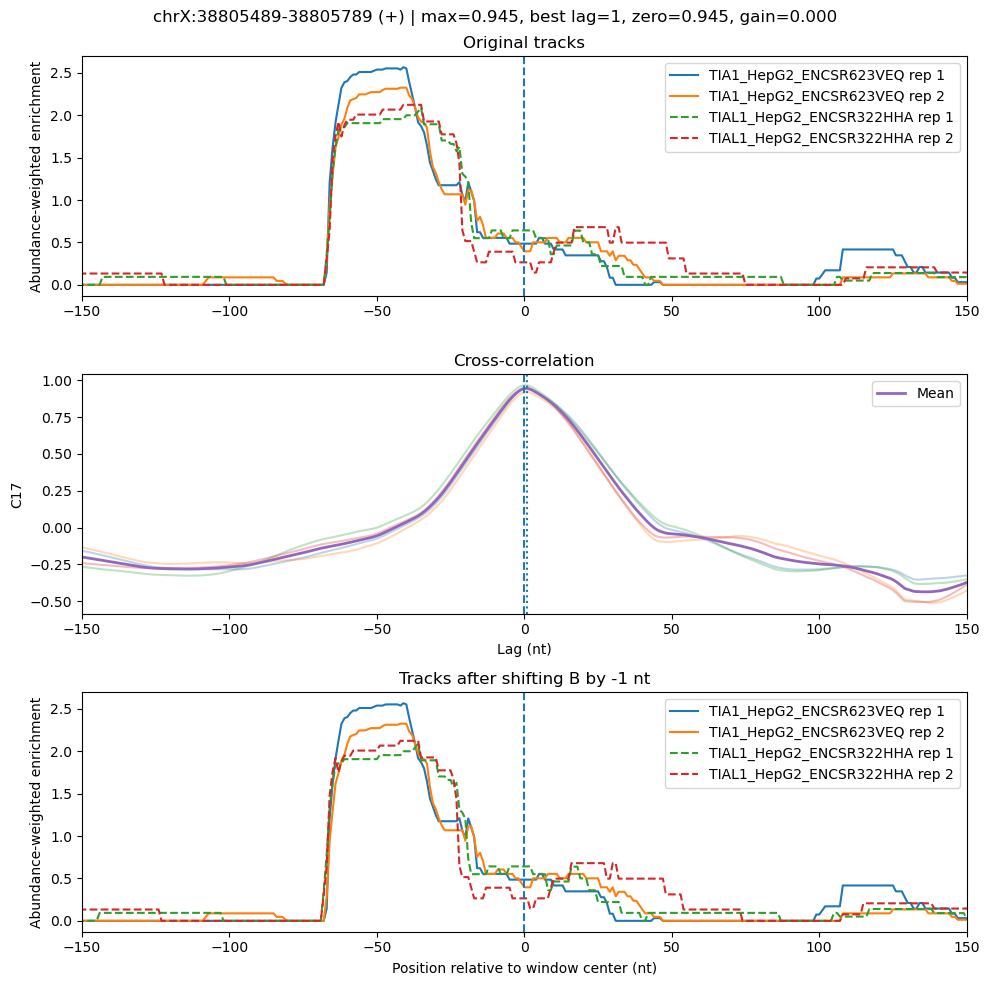

In [13]:
near_zero = metadata[
    metadata["c17_best_lag"].abs() <= 2
].nlargest(5, "c17_max")

for _, row in near_zero.iterrows():
    utils.plot_xcorr_window(row, comparison_data, "c17")

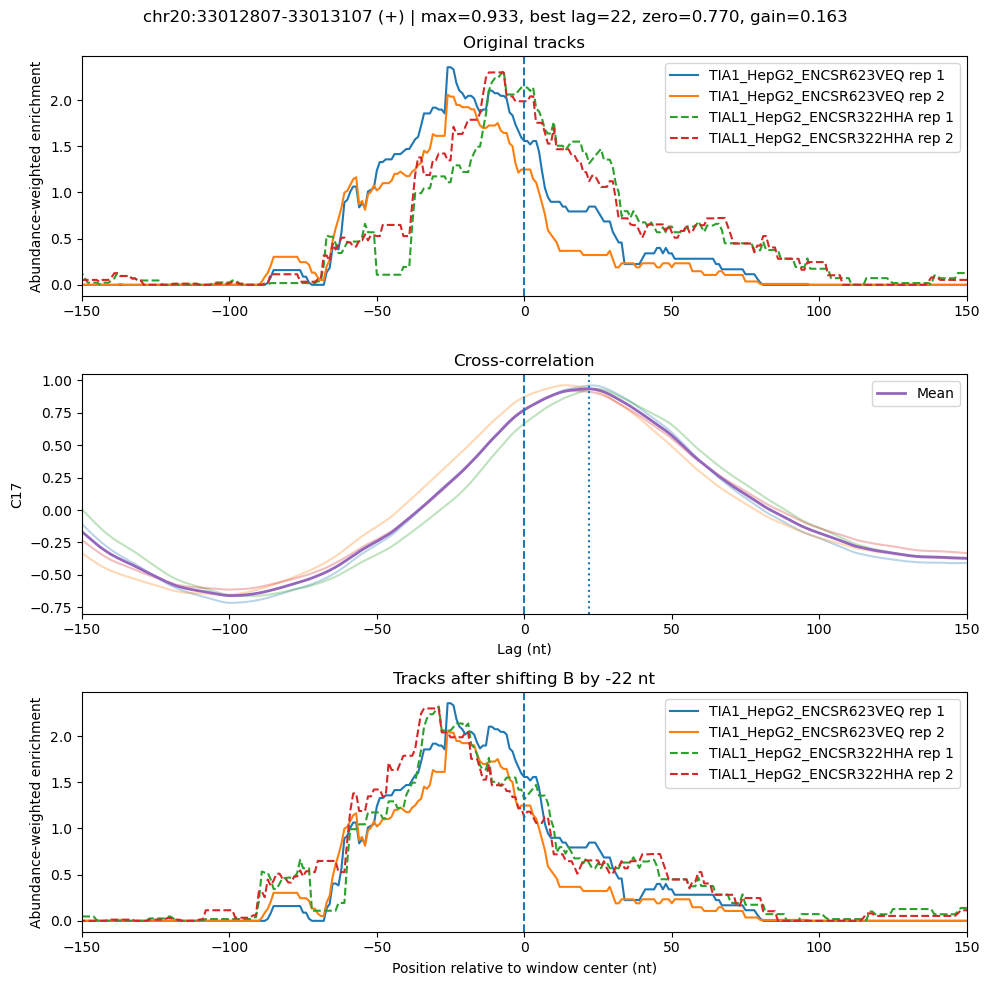

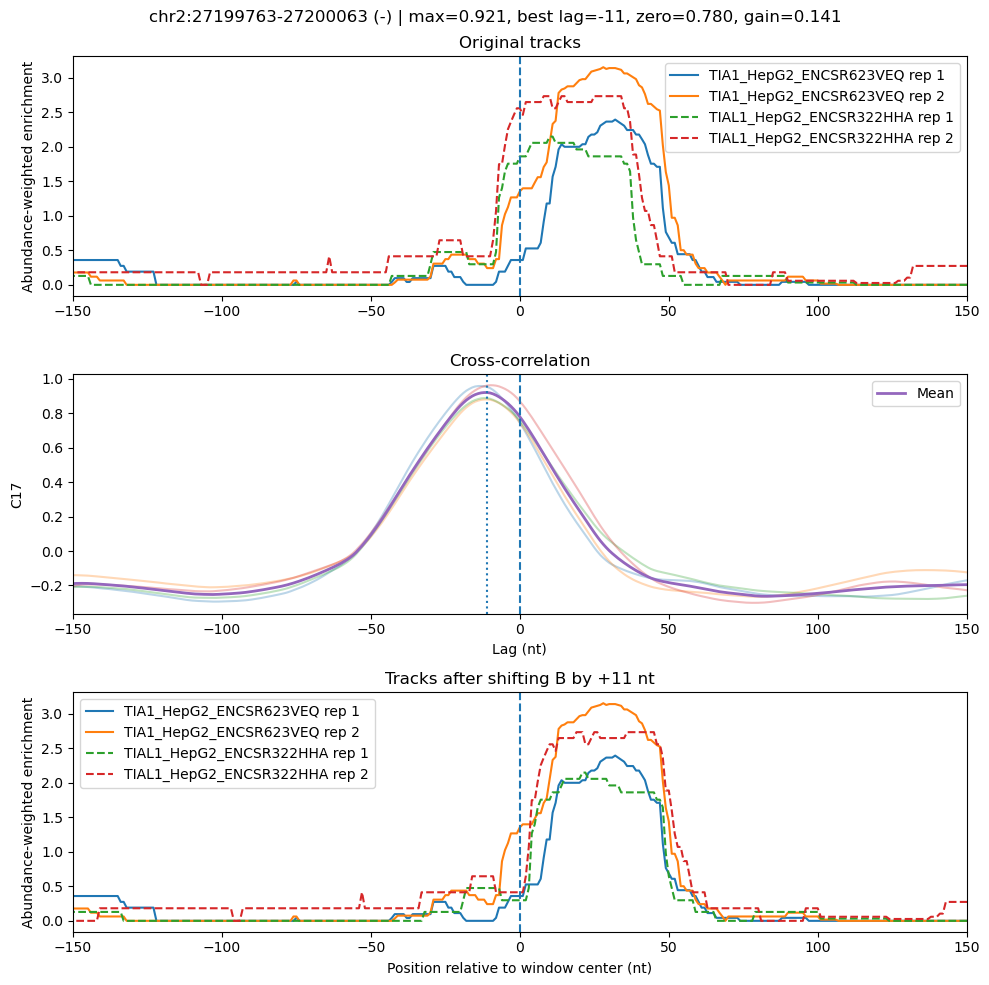

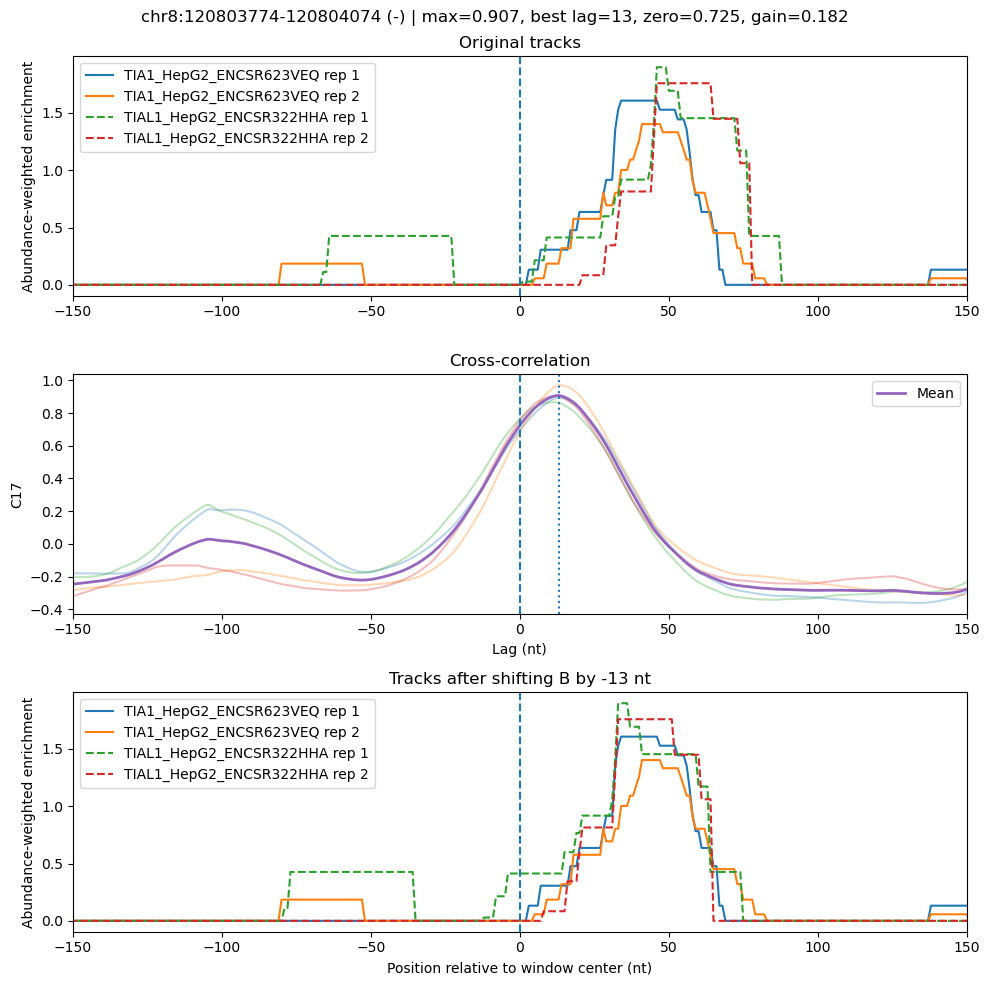

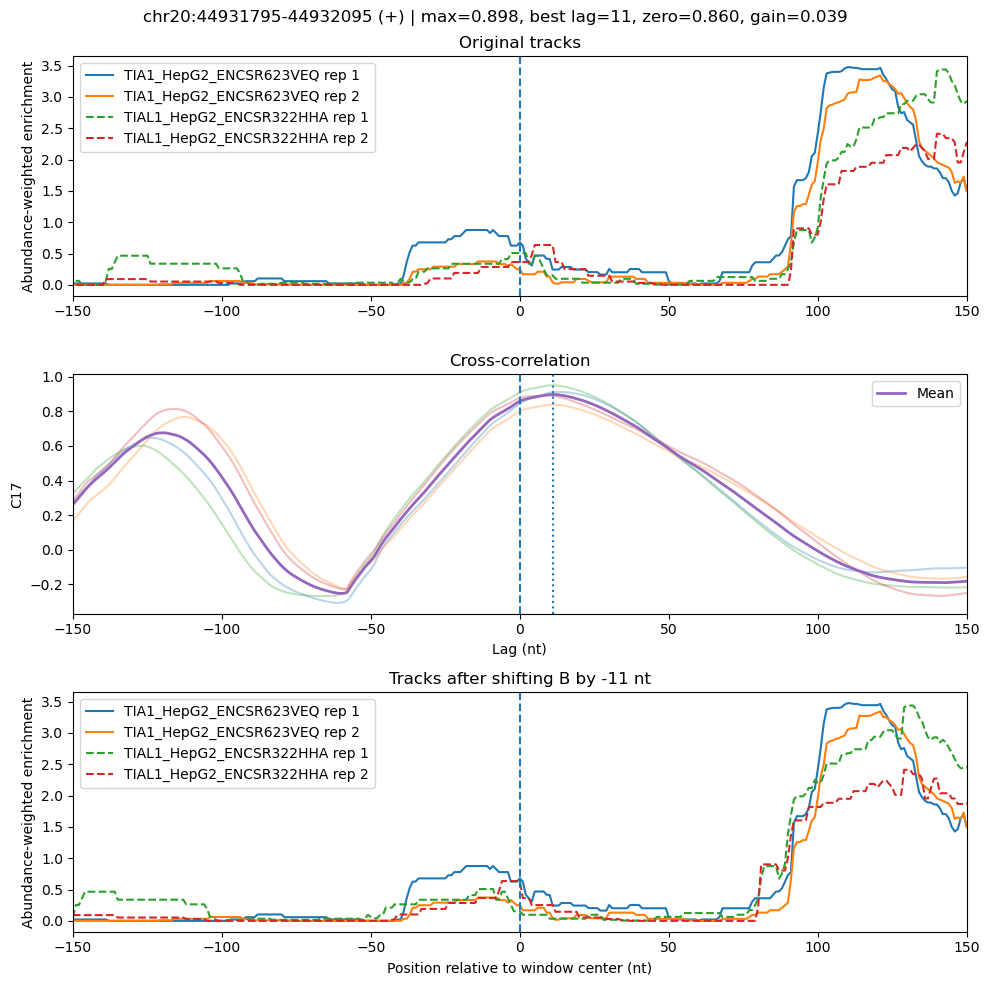

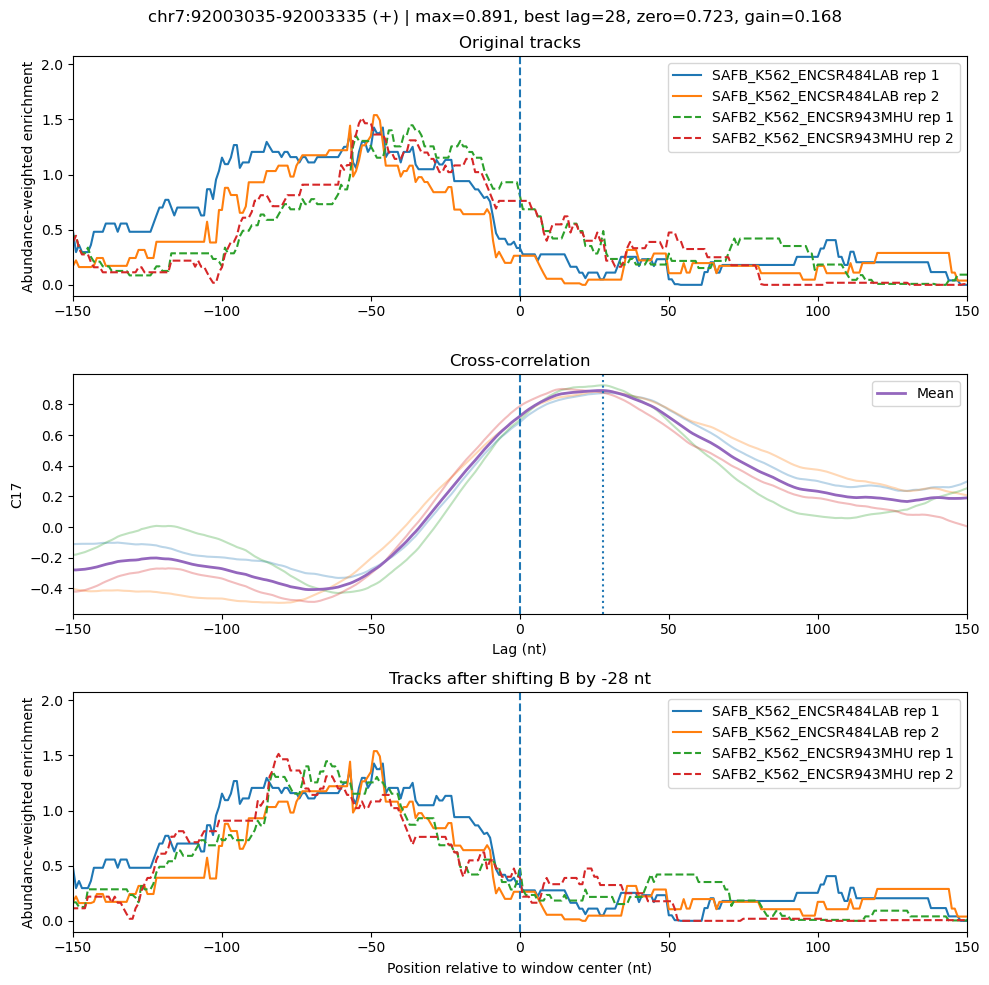

In [14]:
large_lag = metadata[
    metadata["c17_best_lag"].abs() >= 10
].nlargest(5, "c17_max")

for _, row in large_lag.iterrows():
    utils.plot_xcorr_window(row, comparison_data, "c17")

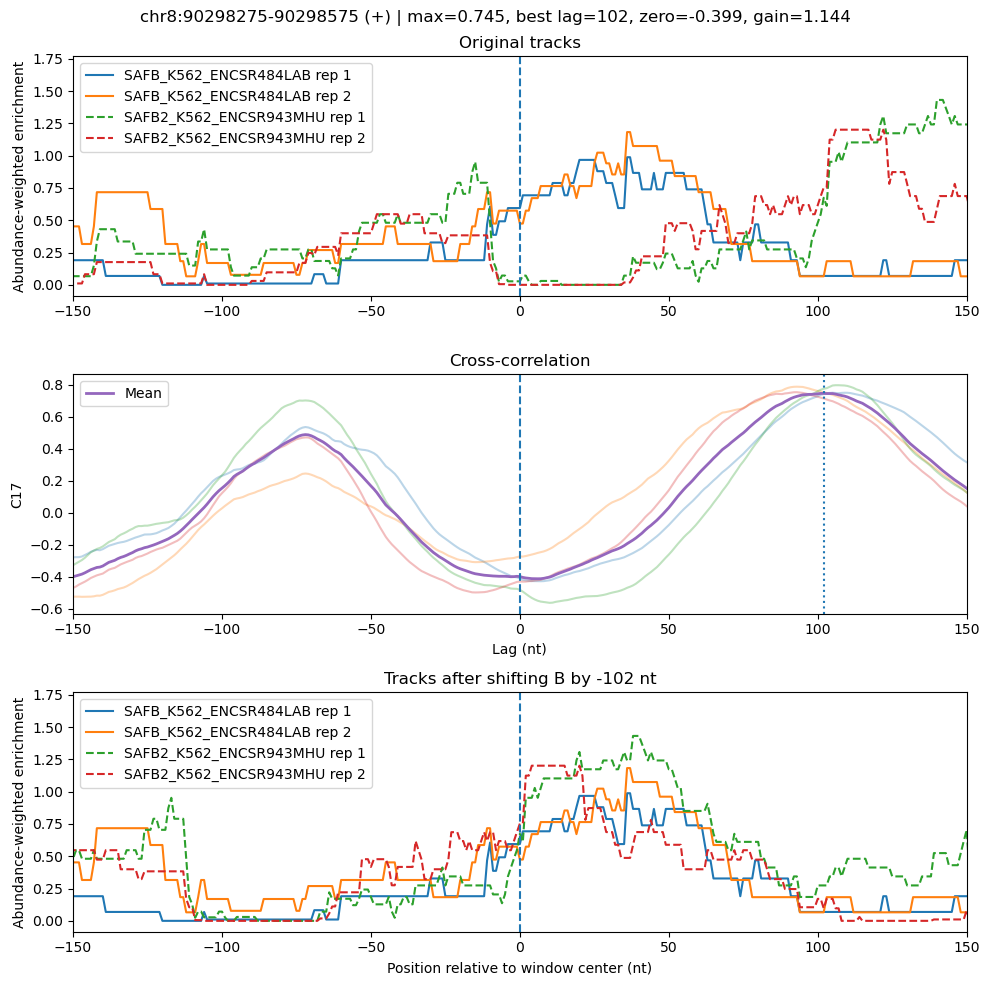

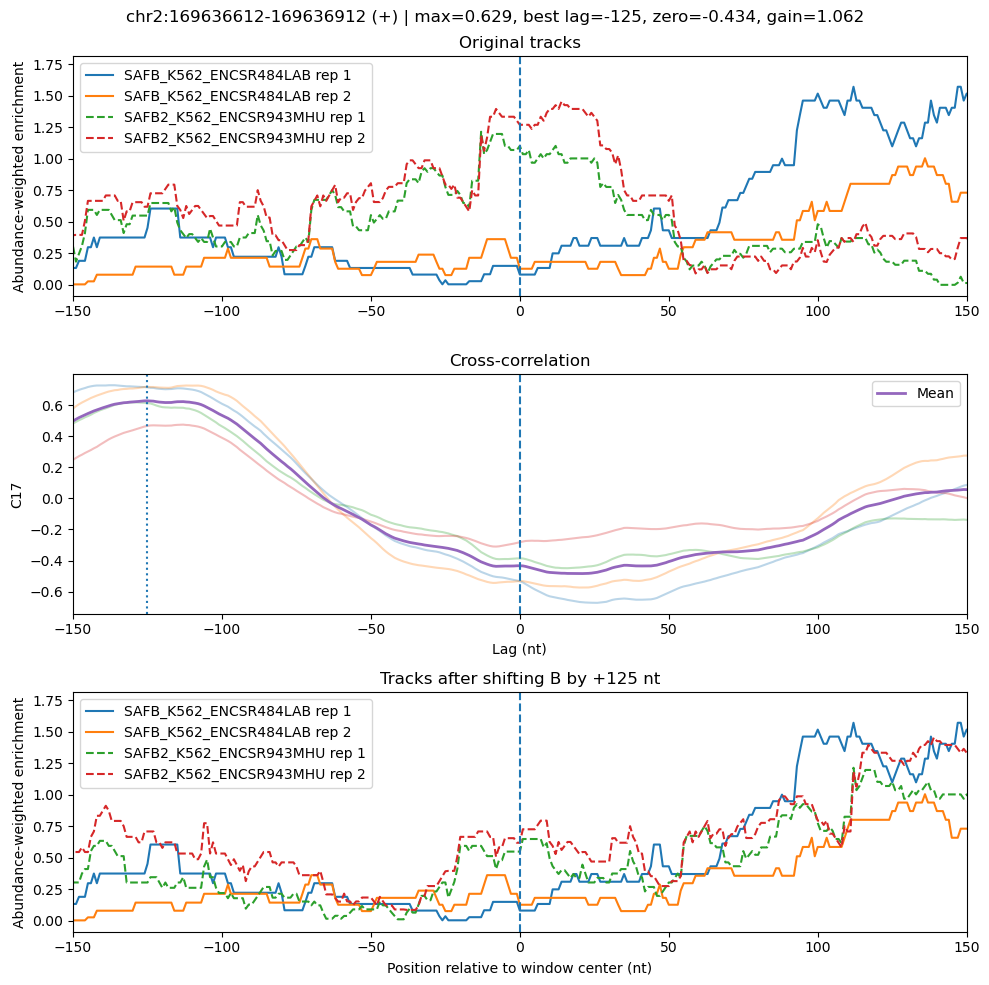

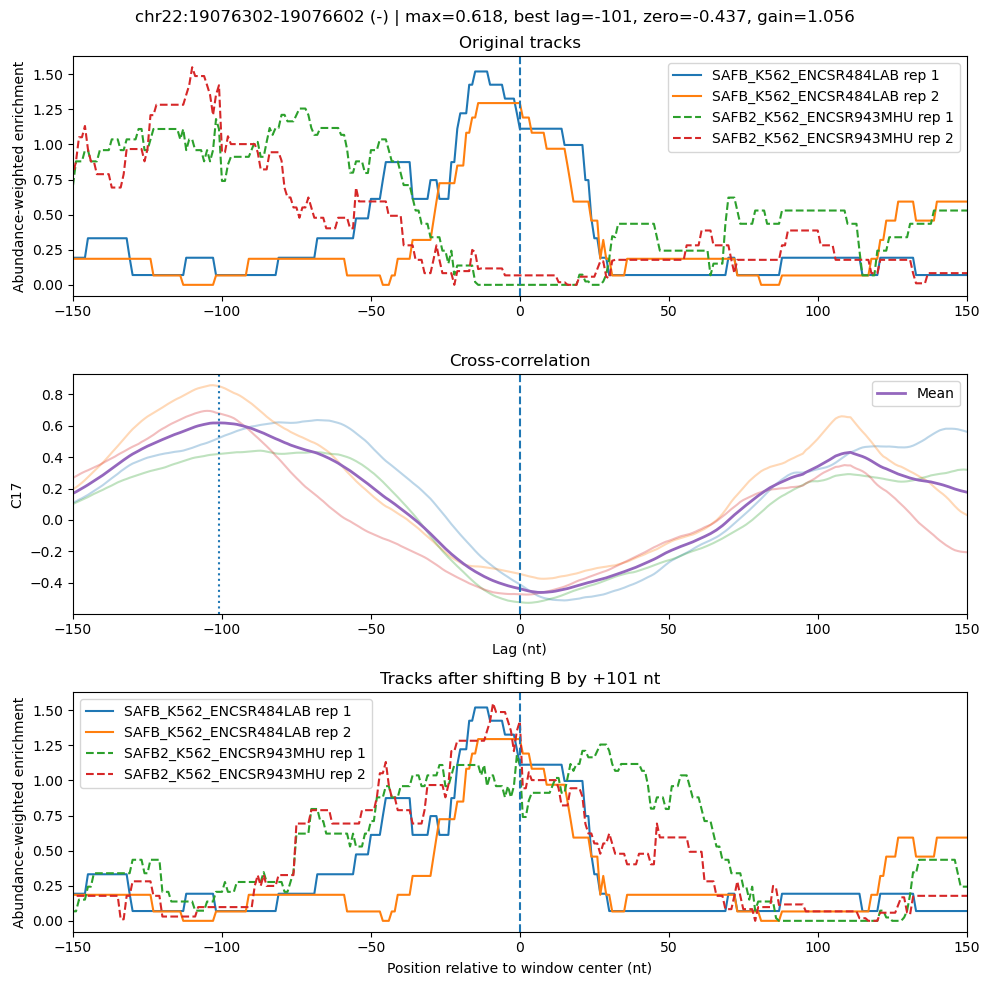

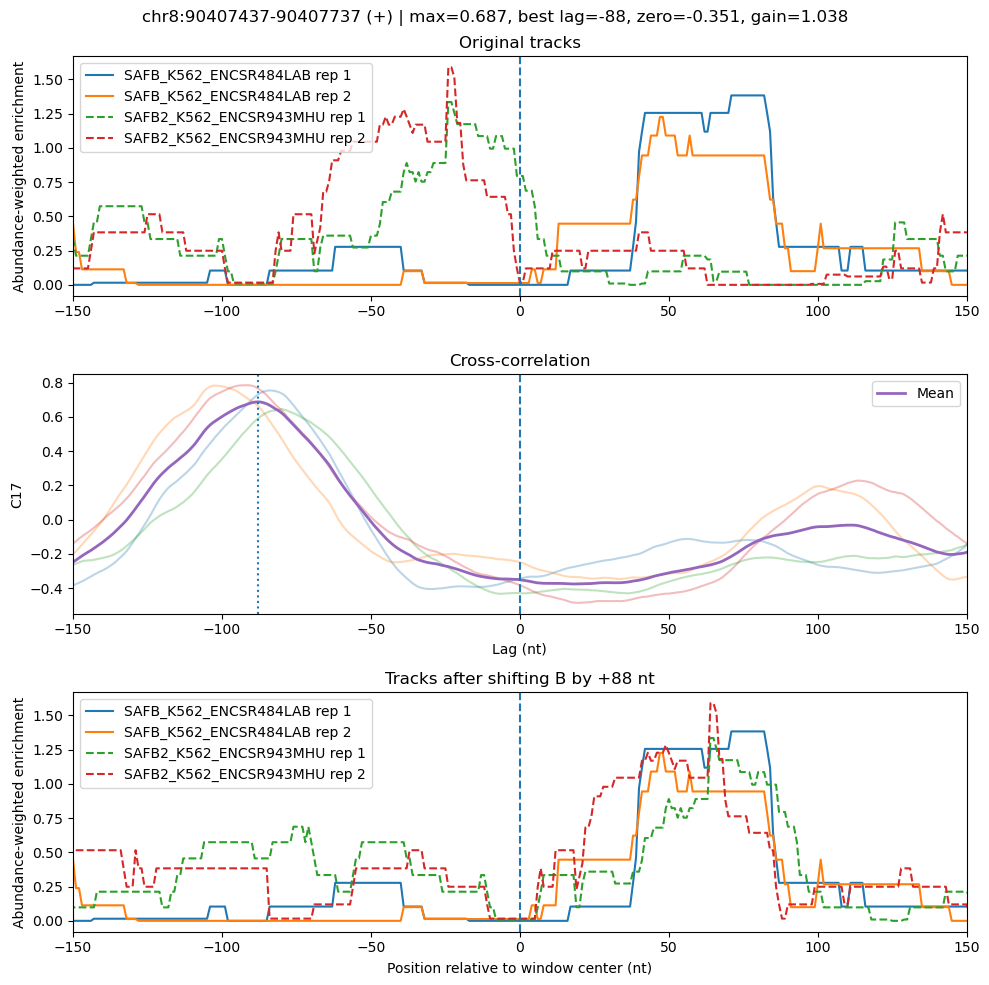

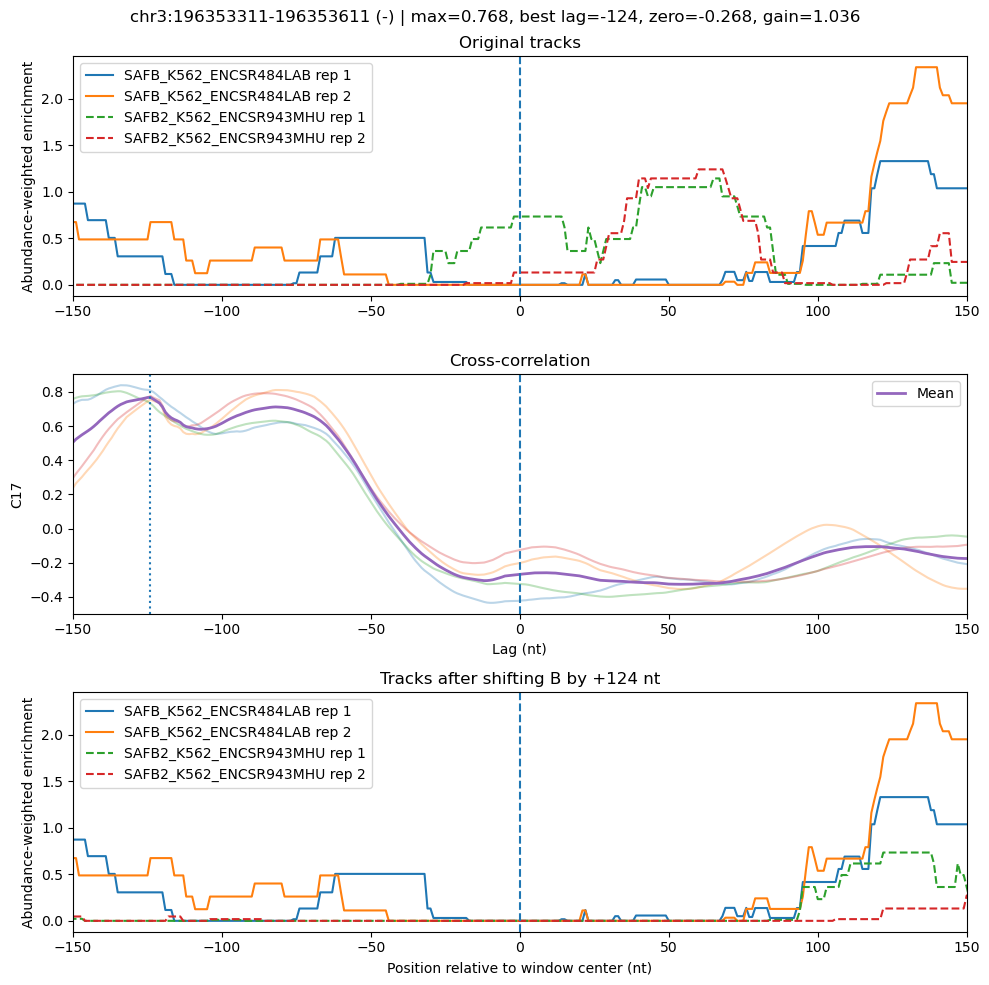

In [15]:
high_gain = metadata.nlargest(5, "c17_gain")

for _, row in high_gain.iterrows():
    utils.plot_xcorr_window(row, comparison_data, "c17")

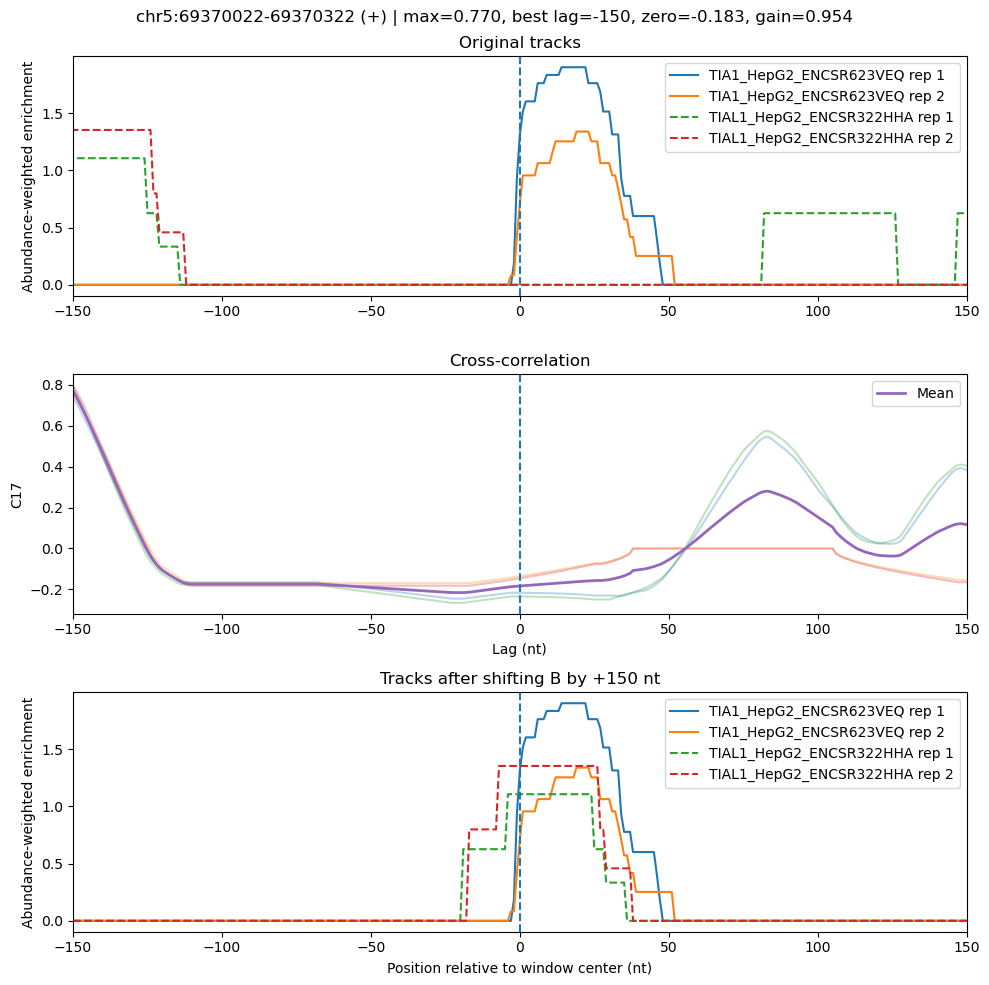

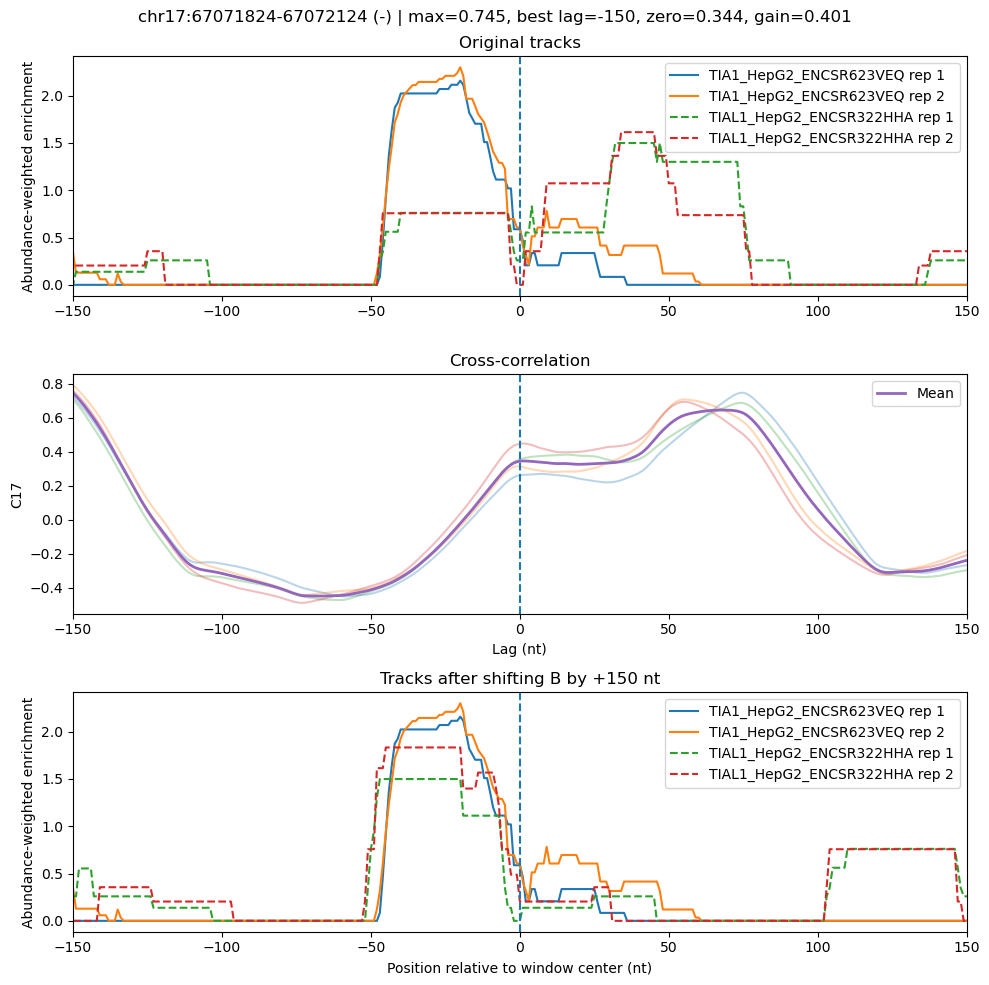

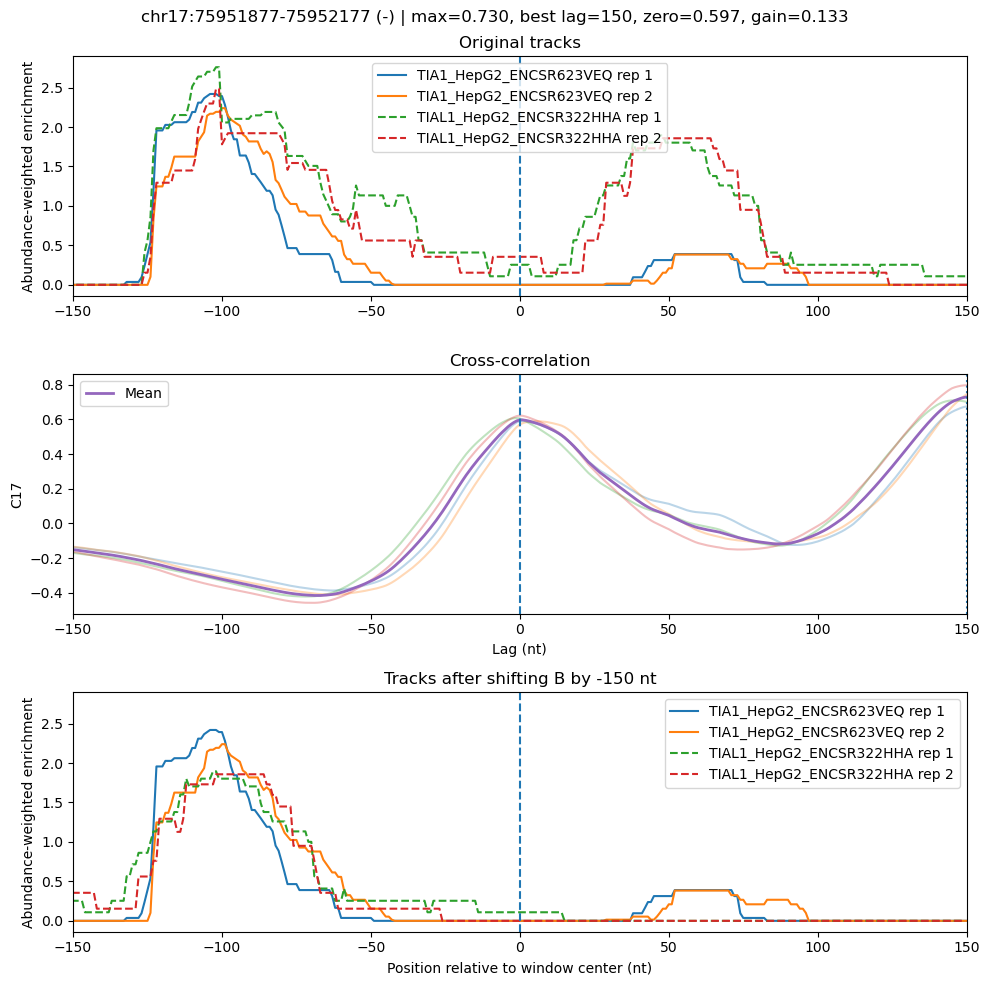

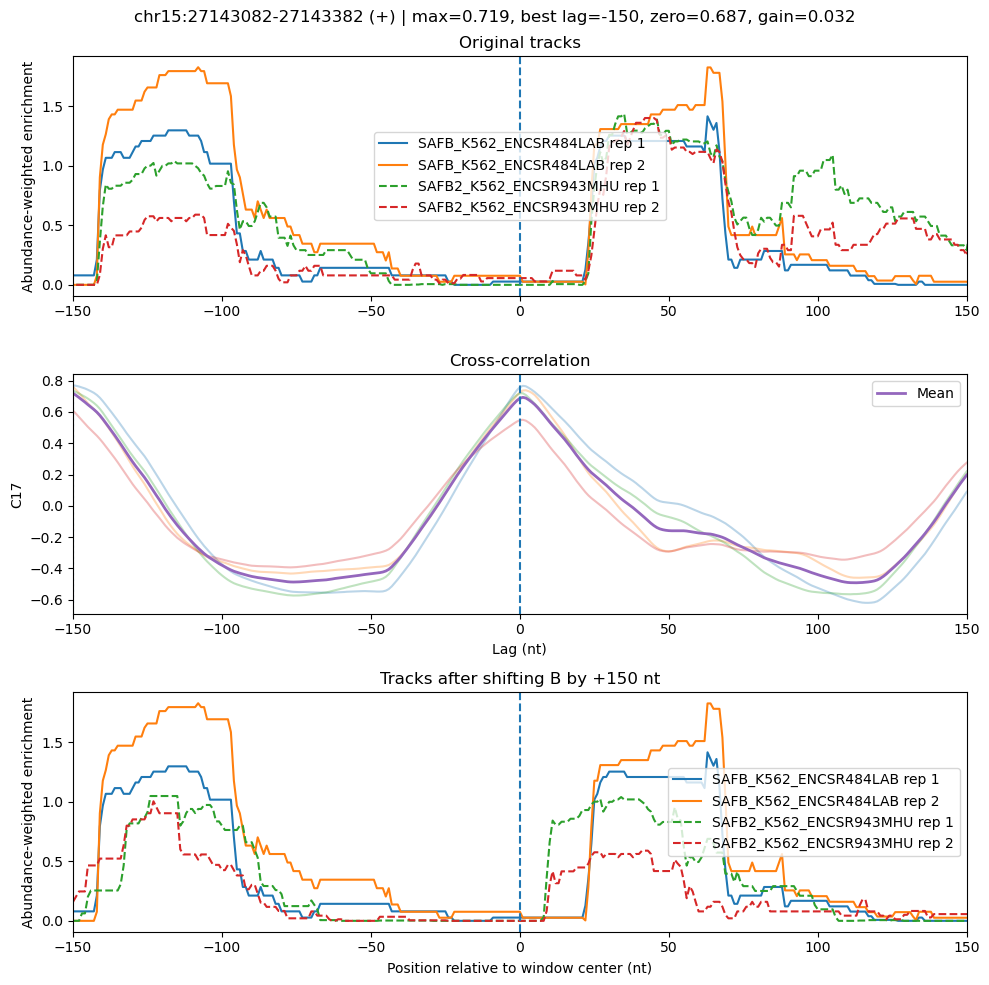

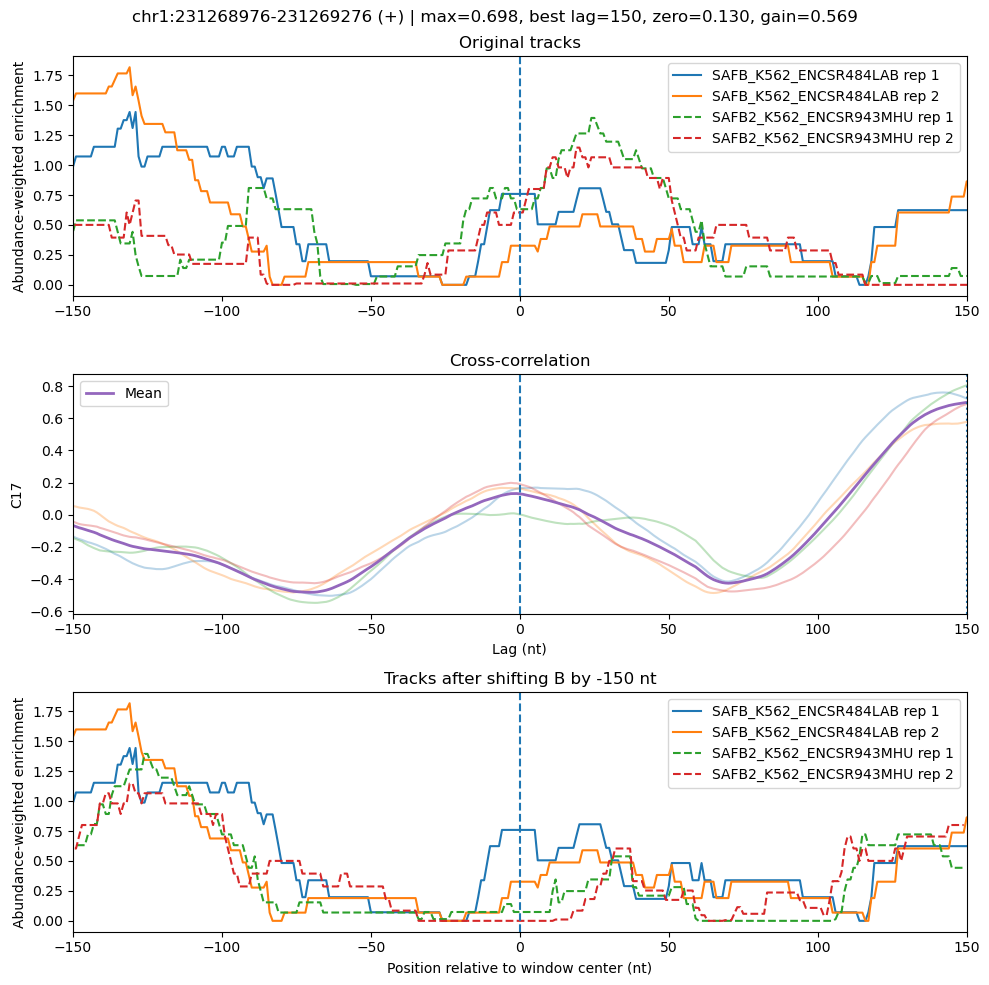

In [16]:
boundary = metadata[
    metadata["c17_best_lag"].abs() == 150
].nlargest(5, "c17_max")

for _, row in boundary.iterrows():
    utils.plot_xcorr_window(row, comparison_data, "c17")

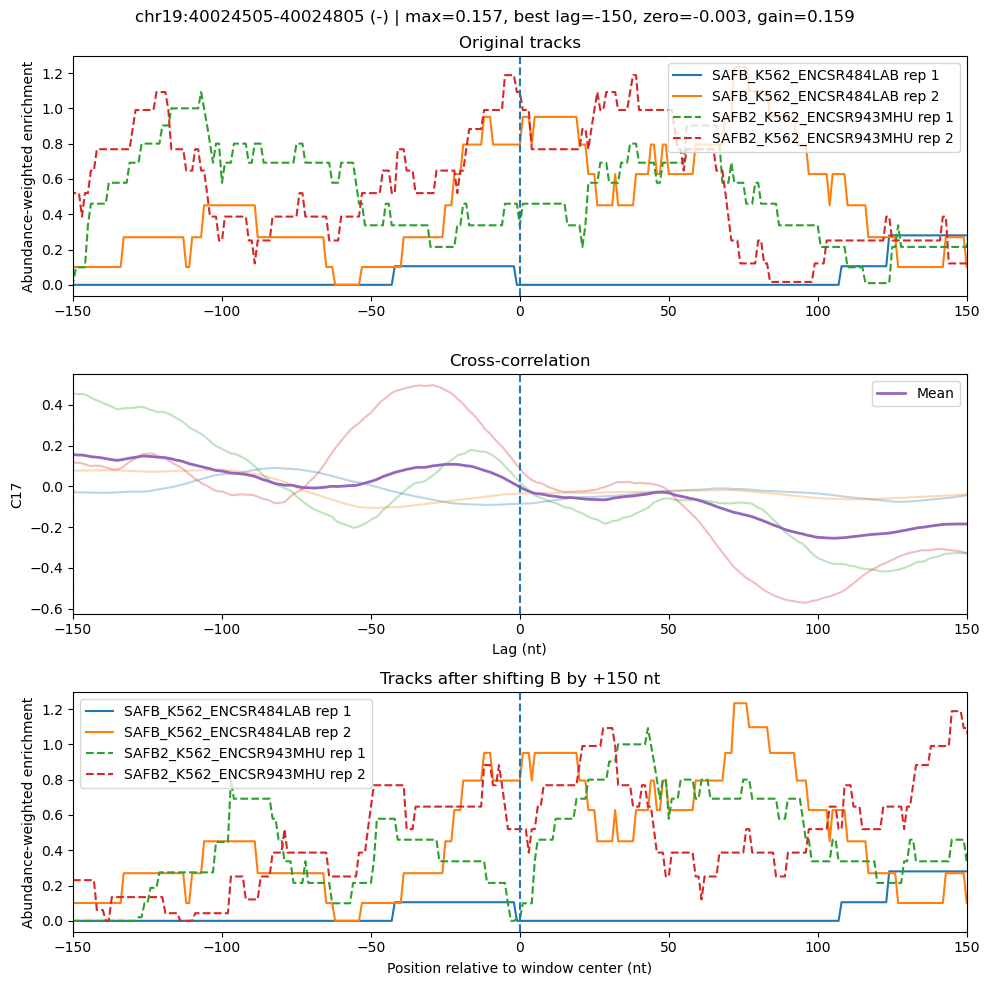

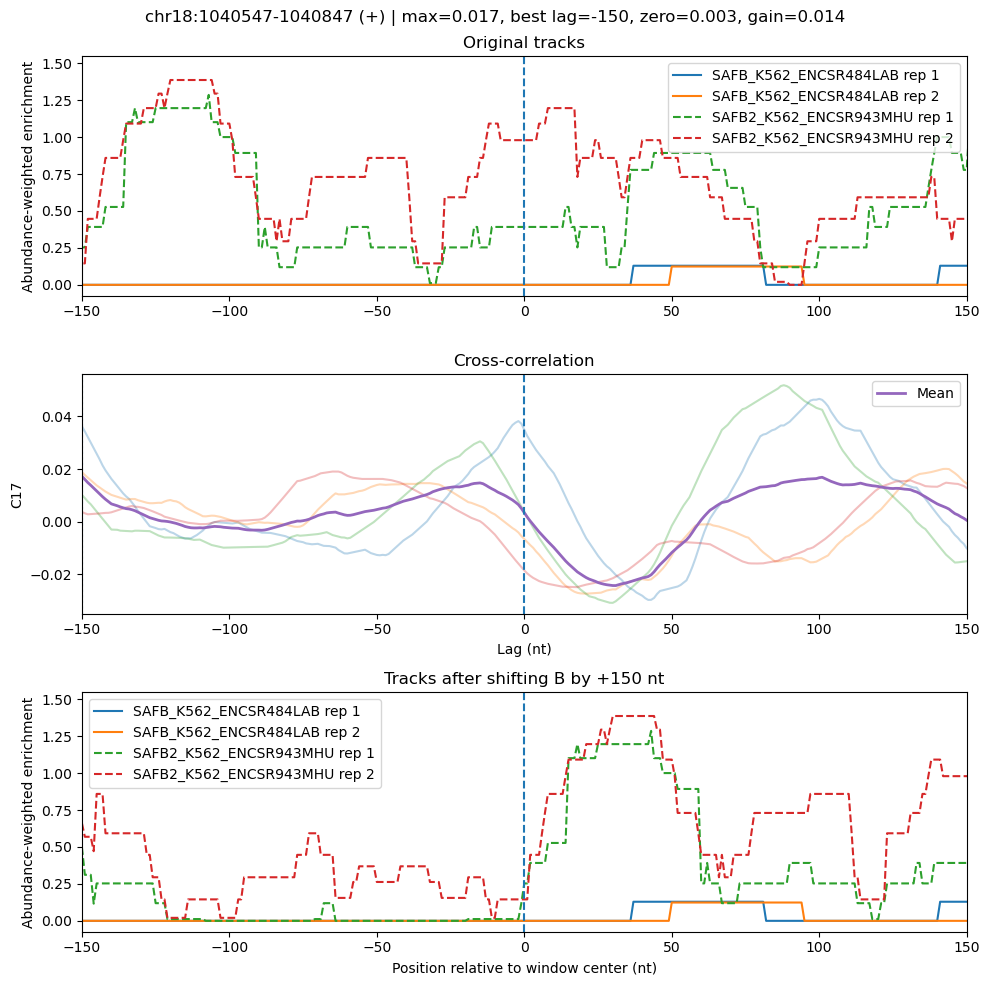

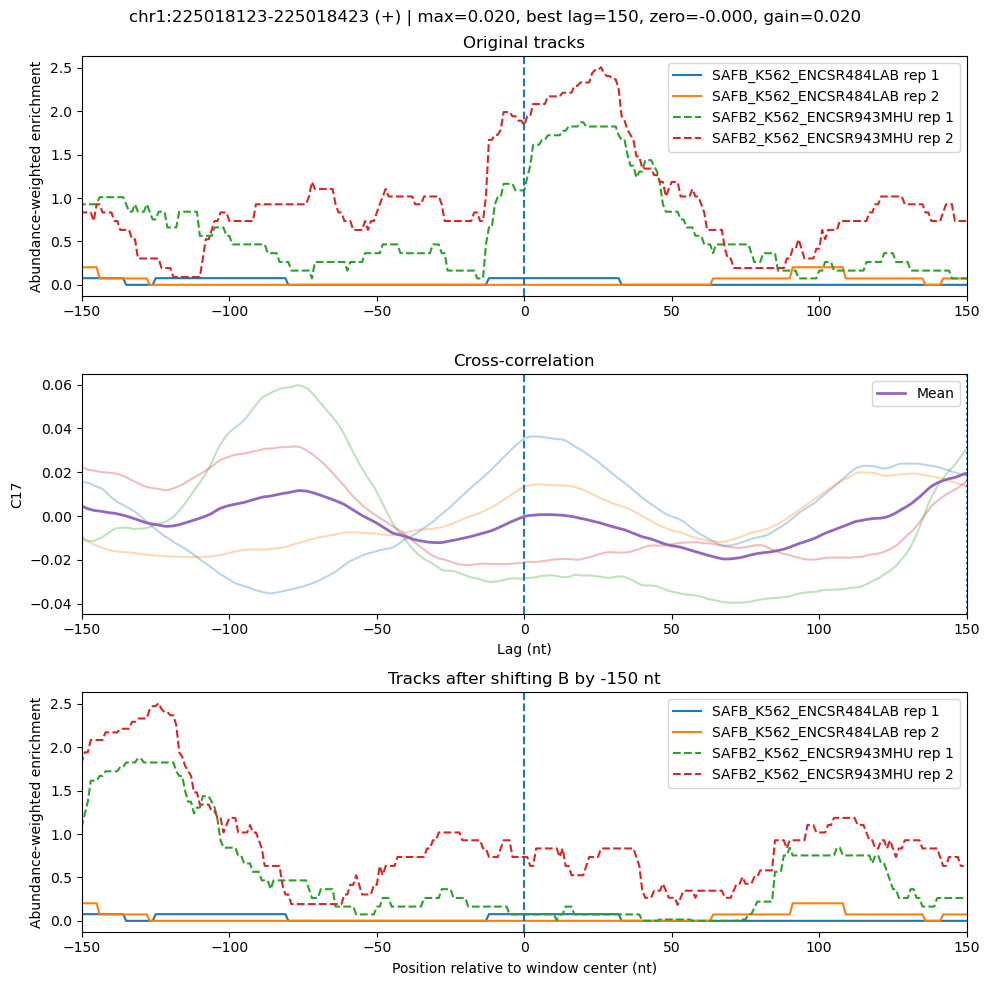

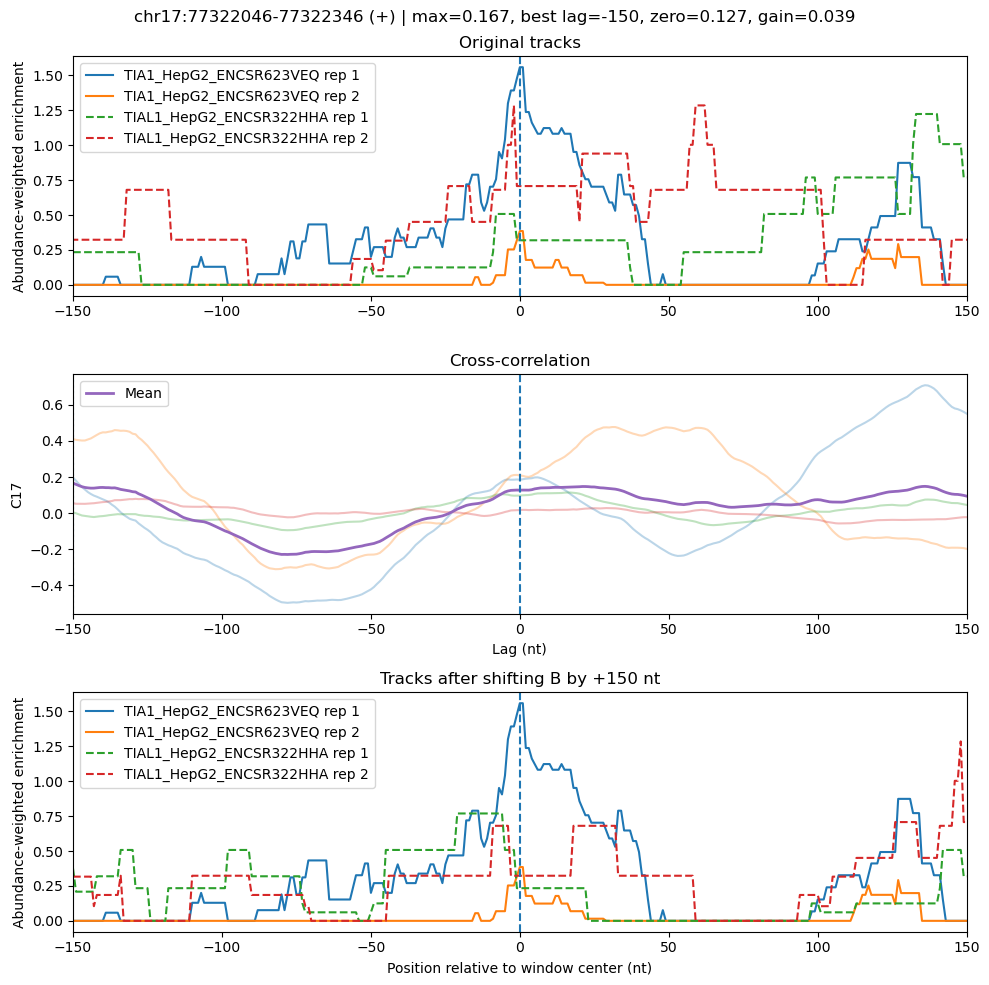

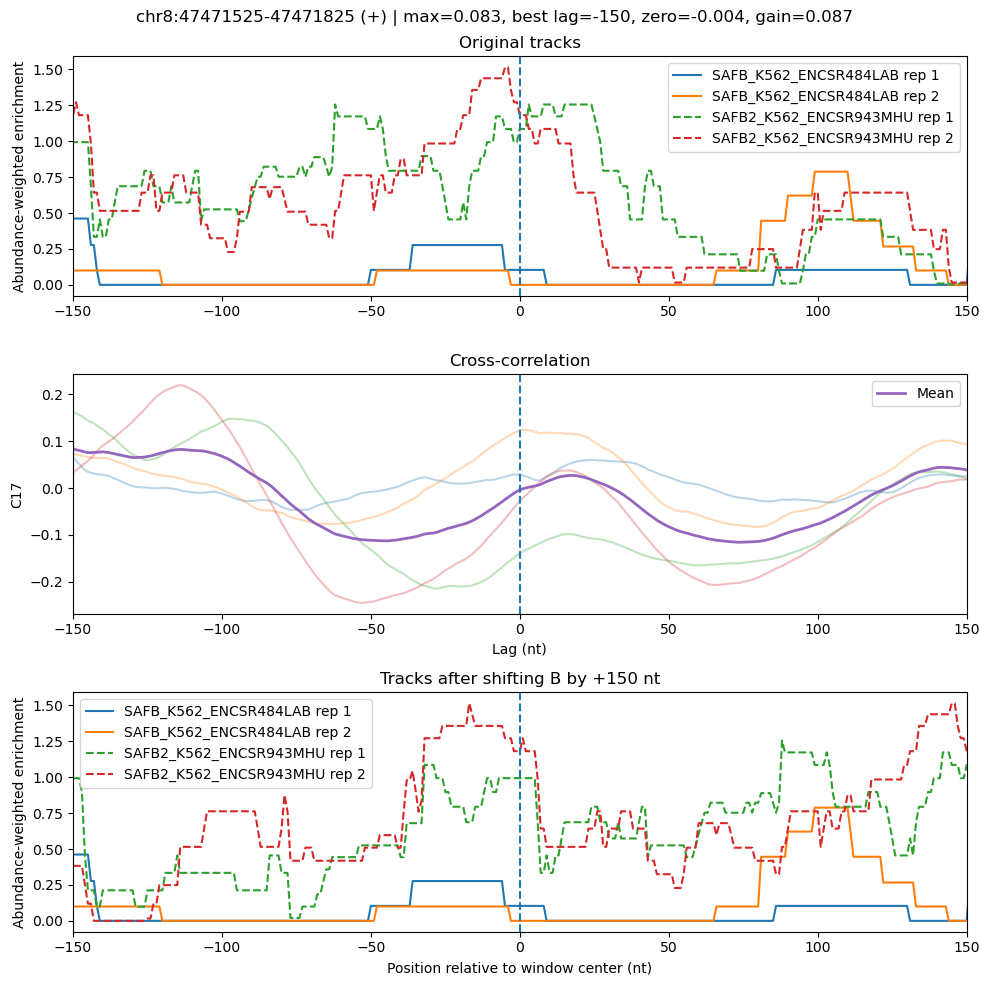

In [17]:
boundary = metadata[
    metadata["c17_best_lag"].abs() == 150
].sample(5, random_state=4)

for _, row in boundary.iterrows():
    utils.plot_xcorr_window(row, comparison_data, "c17")

# Mine width-mismatch examples

For each experiment, calculate self-C17 using the same transformed signals and
lag definition as the main C17 analysis. Width is the contiguous region around
lag 0 that remains above 50% of the zero-lag self-C17 value.

Only diagonal replicate pairings are used for self-C17. This measures each
replicate's autocorrelation scale without mixing replicate disagreement into
the width estimate.

In [18]:
SELF_C17_MAX_LAG = 150
SELF_C17_FRACTION = 0.5
SELF_C17_BATCH_SIZE = 2000


def mean_diagonal_c17(c17):
    """Mean of A-replicate i versus B-replicate i curves."""
    replicate_idx = np.arange(min(c17.shape[1], c17.shape[2]))
    diagonal = c17[:, replicate_idx, replicate_idx, :]

    valid = np.isfinite(diagonal)
    counts = valid.sum(axis=1)
    totals = np.where(valid, diagonal, 0).sum(axis=1)

    return np.divide(
        totals,
        counts,
        out=np.full(totals.shape, np.nan, dtype=np.float32),
        where=counts > 0
    )


def central_self_c17_widths(curves, lags, fraction=0.5):
    """
    Measure the contiguous above-threshold interval containing lag 0.

    The returned width counts lag positions, so a curve that falls below the
    threshold immediately on both sides of zero has width 1.
    """
    zero_idx = np.where(lags == 0)[0][0]

    widths = np.full(len(curves), np.nan)
    left_lags = np.full(len(curves), np.nan)
    right_lags = np.full(len(curves), np.nan)
    censored = np.zeros(len(curves), dtype=bool)

    for i, curve in enumerate(curves):
        center = curve[zero_idx]

        if not np.isfinite(center) or center <= 0:
            continue

        above = np.isfinite(curve) & (curve >= fraction * center)

        if not above[zero_idx]:
            continue

        left = zero_idx
        while left > 0 and above[left - 1]:
            left -= 1

        right = zero_idx
        while right < len(lags) - 1 and above[right + 1]:
            right += 1

        left_lags[i] = lags[left]
        right_lags[i] = lags[right]
        widths[i] = lags[right] - lags[left] + 1
        censored[i] = left == 0 or right == len(lags) - 1

    return {
        "width": widths,
        "left_lag": left_lags,
        "right_lag": right_lags,
        "censored": censored
    }


def summarize_self_c17_widths(
    signal,
    max_lag=150,
    fraction=0.5,
    batch_size=2000
):
    """
    Calculate self-C17 in batches and retain only width summaries.

    Batching avoids keeping two additional full four-dimensional C17 arrays
    in comparison_data.
    """
    if len(signal) == 0:
        raise ValueError("Cannot summarize an empty signal array.")

    summaries = {
        "width": [],
        "left_lag": [],
        "right_lag": [],
        "censored": []
    }

    for start in range(0, len(signal), batch_size):
        stop = min(start + batch_size, len(signal))

        self_c17, lags = utils.C17(
            signal[start:stop],
            signal[start:stop],
            max_lag=max_lag
        )

        mean_curves = mean_diagonal_c17(self_c17)
        batch_summary = central_self_c17_widths(
            mean_curves,
            lags,
            fraction=fraction
        )

        for key in summaries:
            summaries[key].append(batch_summary[key])

    for key in summaries:
        summaries[key] = np.concatenate(summaries[key])

    summaries["lags"] = lags
    return summaries

In [19]:
for side in ["A", "B"]:
    metadata[f"c17_self_width_{side}"] = np.nan
    metadata[f"c17_self_left_{side}"] = np.nan
    metadata[f"c17_self_right_{side}"] = np.nan
    metadata[f"c17_self_censored_{side}"] = False


for comparison_id, comp in comparison_data.items():
    self_A = summarize_self_c17_widths(
        comp["signal_A"],
        max_lag=SELF_C17_MAX_LAG,
        fraction=SELF_C17_FRACTION,
        batch_size=SELF_C17_BATCH_SIZE
    )

    self_B = summarize_self_c17_widths(
        comp["signal_B"],
        max_lag=SELF_C17_MAX_LAG,
        fraction=SELF_C17_FRACTION,
        batch_size=SELF_C17_BATCH_SIZE
    )

    mask = metadata["comparison_id"] == comparison_id
    order = metadata.loc[mask, "window_idx"].to_numpy()

    for side, summary in [("A", self_A), ("B", self_B)]:
        metadata.loc[mask, f"c17_self_width_{side}"] = (
            summary["width"][order]
        )
        metadata.loc[mask, f"c17_self_left_{side}"] = (
            summary["left_lag"][order]
        )
        metadata.loc[mask, f"c17_self_right_{side}"] = (
            summary["right_lag"][order]
        )
        metadata.loc[mask, f"c17_self_censored_{side}"] = (
            summary["censored"][order]
        )


width_A = metadata["c17_self_width_A"]
width_B = metadata["c17_self_width_B"]

narrow_width = np.minimum(width_A, width_B)
broad_width = np.maximum(width_A, width_B)

metadata["c17_self_width_ratio"] = broad_width / narrow_width
metadata["c17_self_log2_width_ratio"] = np.log2(
    metadata["c17_self_width_ratio"]
)

metadata["c17_self_broader_track"] = pd.Series(
    pd.NA,
    index=metadata.index,
    dtype="string"
)

valid_widths = width_A.notna() & width_B.notna()
metadata.loc[valid_widths, "c17_self_broader_track"] = np.where(
    width_A[valid_widths] >= width_B[valid_widths],
    "A",
    "B"
)

In [20]:
MIN_CROSS_C17 = 0.4
MAX_ABS_BEST_LAG = 10
MIN_WIDTH_RATIO = 2.0
MIN_NARROW_WIDTH = 3

narrow_width = metadata[
    ["c17_self_width_A", "c17_self_width_B"]
].min(axis=1)

width_candidates = metadata[
    (metadata["c17_max"] >= MIN_CROSS_C17) &
    (metadata["c17_best_lag"].abs() <= MAX_ABS_BEST_LAG) &
    (metadata["c17_self_width_ratio"] >= MIN_WIDTH_RATIO) &
    (narrow_width >= MIN_NARROW_WIDTH) &
    (~metadata["c17_self_censored_A"]) &
    (~metadata["c17_self_censored_B"])
].sort_values(
    ["c17_self_width_ratio", "c17_max"],
    ascending=[False, False]
)

candidate_columns = [
    "comparison_id",
    "window_idx",
    "region_id",
    "experiment_A",
    "experiment_B",
    "chrom",
    "start",
    "end",
    "strand",
    "c17_max",
    "c17_best_lag",
    "c17_self_width_A",
    "c17_self_width_B",
    "c17_self_width_ratio",
    "c17_self_broader_track"
]

print("Width-mismatch candidates:", len(width_candidates))
display(width_candidates[candidate_columns].head(20))

Width-mismatch candidates: 225


,comparison_id,window_idx,region_id,experiment_A,experiment_B,chrom,start,end,strand,c17_max,c17_best_lag,c17_self_width_A,c17_self_width_B,c17_self_width_ratio,c17_self_broader_track
29445,4,15248,8403,SAFB_K562_ENCSR484LAB,SAFB2_K562_ENCSR943MHU,chr18,77982519,77982819,-,0.508964,0.0,34.0,194.0,5.705882,B
13076,3,13076,9406,TIA1_HepG2_ENCSR623VEQ,TIAL1_HepG2_ENCSR322HHA,chr8,61502581,61502881,-,0.452289,7.0,42.0,188.0,4.476190,B
47973,4,33776,18323,SAFB_K562_ENCSR484LAB,SAFB2_K562_ENCSR943MHU,chr7,121199725,121200025,+,0.540431,2.0,121.0,29.0,4.172414,A
35665,4,21468,11872,SAFB_K562_ENCSR484LAB,SAFB2_K562_ENCSR943MHU,chr21,38036116,38036416,-,0.402797,0.0,48.0,195.0,4.062500,B
11216,3,11216,8095,TIA1_HepG2_ENCSR623VEQ,TIAL1_HepG2_ENCSR322HHA,chr6,1314003,1314303,+,0.414002,1.0,41.0,166.0,4.048780,B
9307,3,9307,6683,TIA1_HepG2_ENCSR623VEQ,TIAL1_HepG2_ENCSR322HHA,chr21,25880729,25881029,-,0.652527,3.0,160.0,41.0,3.902439,A
2611,3,2611,1903,TIA1_HepG2_ENCSR623VEQ,TIAL1_HepG2_ENCSR322HHA,chr13,29509412,29509712,-,0.672307,0.0,46.0,169.0,3.673913,B
11897,3,11897,8582,TIA1_HepG2_ENCSR623VEQ,TIAL1_HepG2_ENCSR322HHA,chr6,119179718,119180018,-,0.862137,3.0,50.0,183.0,3.660000,B
6725,3,6725,4799,TIA1_HepG2_ENCSR623VEQ,TIAL1_HepG2_ENCSR322HHA,chr19,56812774,56813074,-,0.798082,-1.0,44.0,161.0,3.659091,B
48641,4,34444,18676,SAFB_K562_ENCSR484LAB,SAFB2_K562_ENCSR943MHU,chr7,5708662,5708962,-,0.444033,-1.0,19.0,69.0,3.631579,B


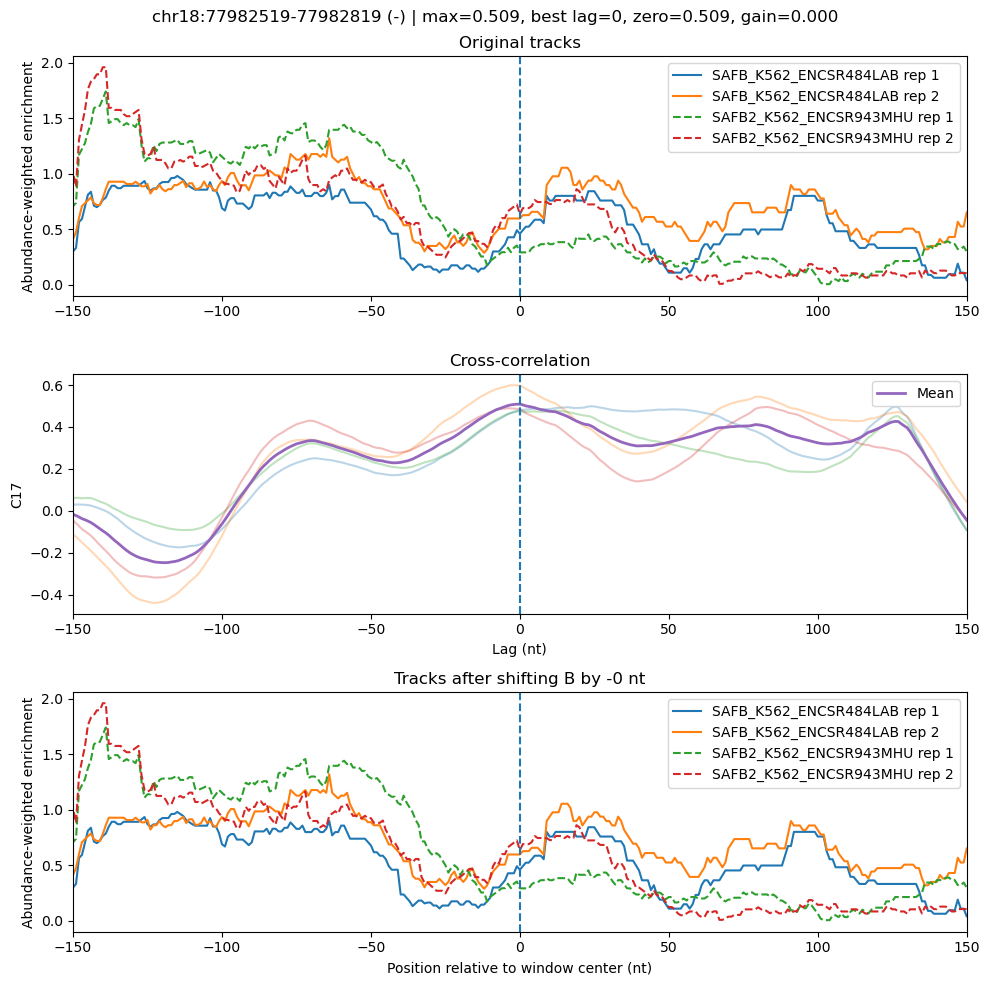

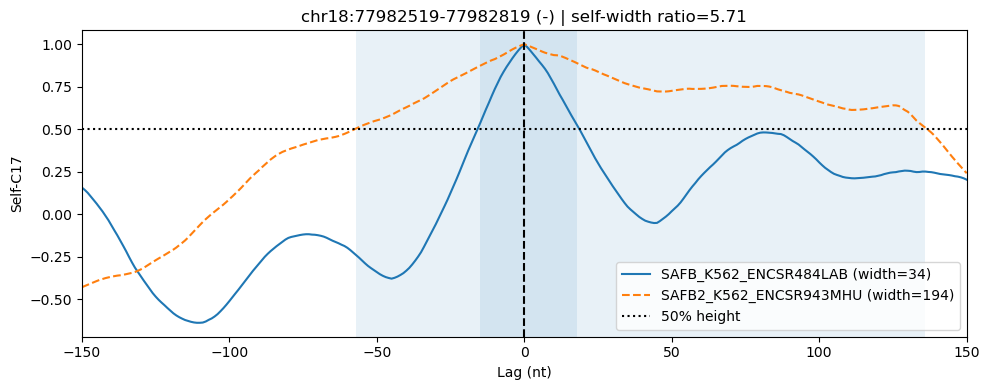

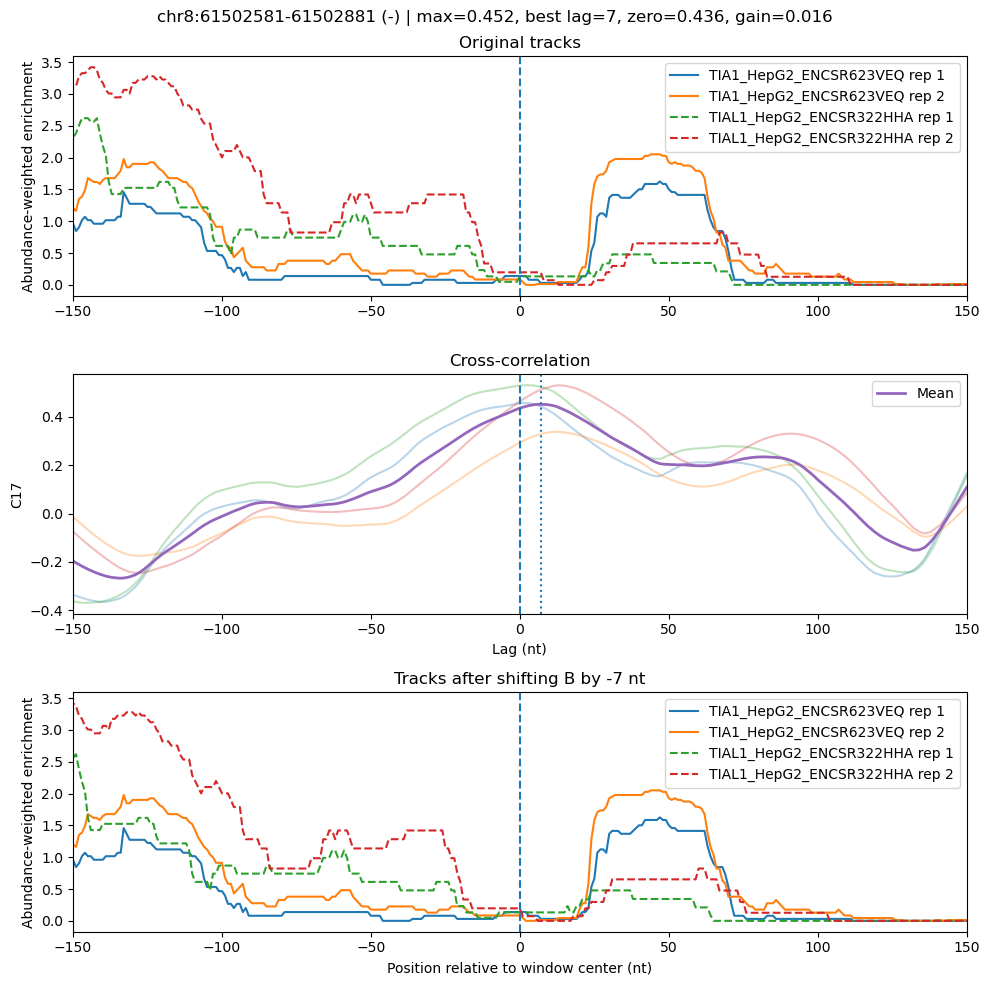

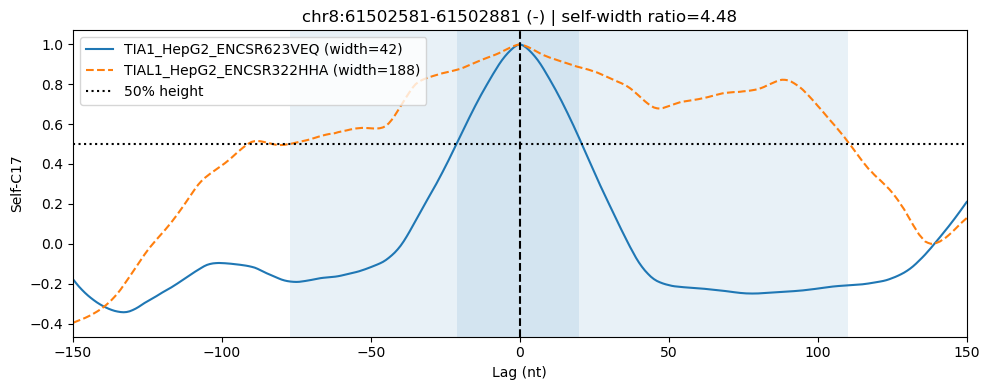

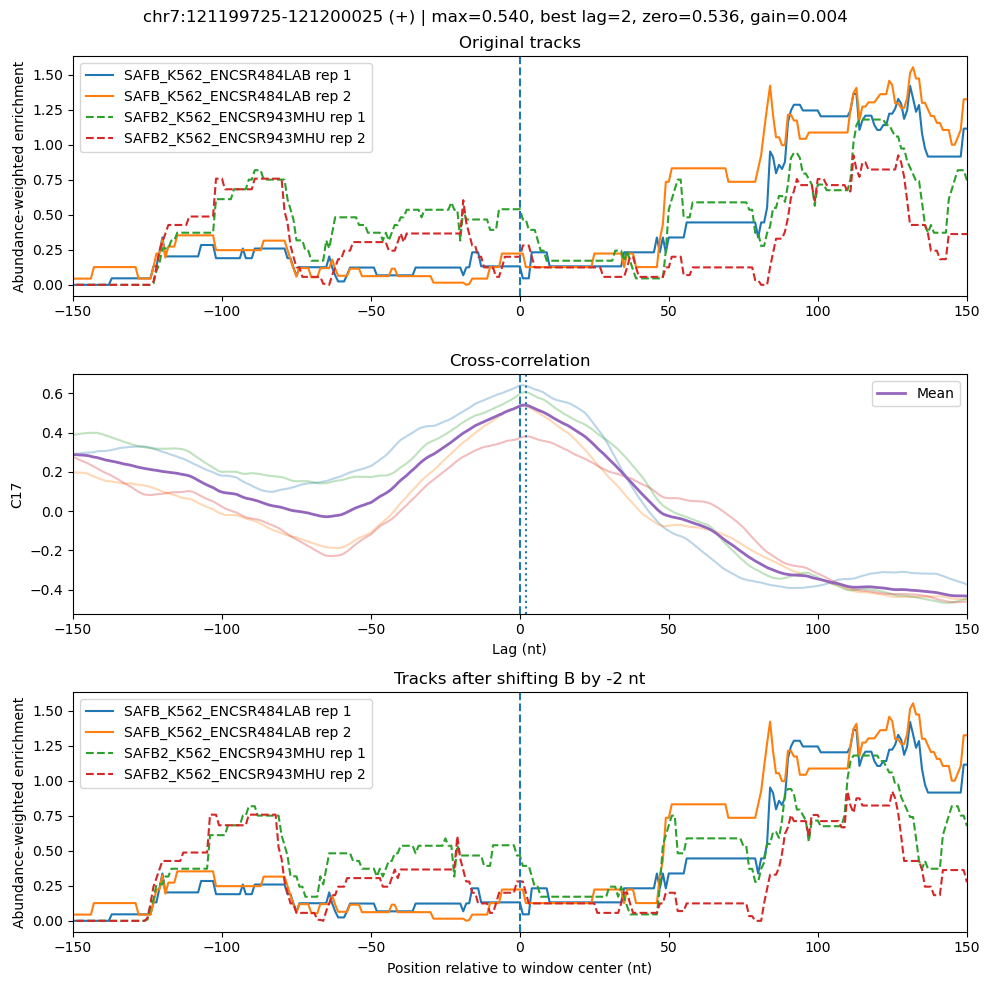

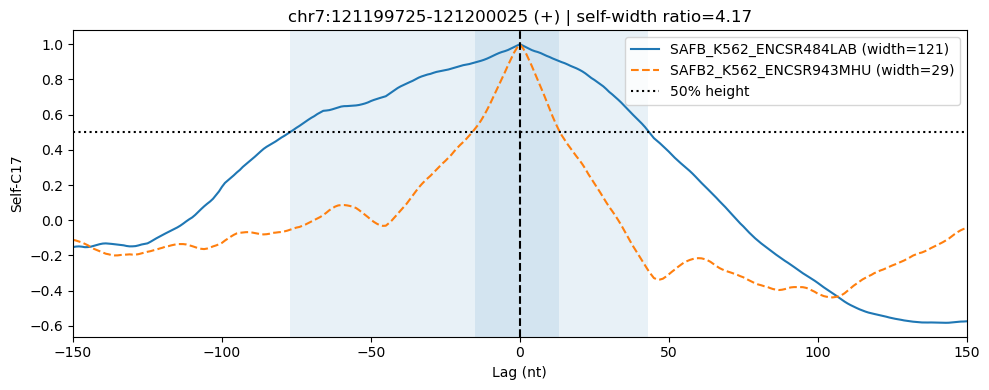

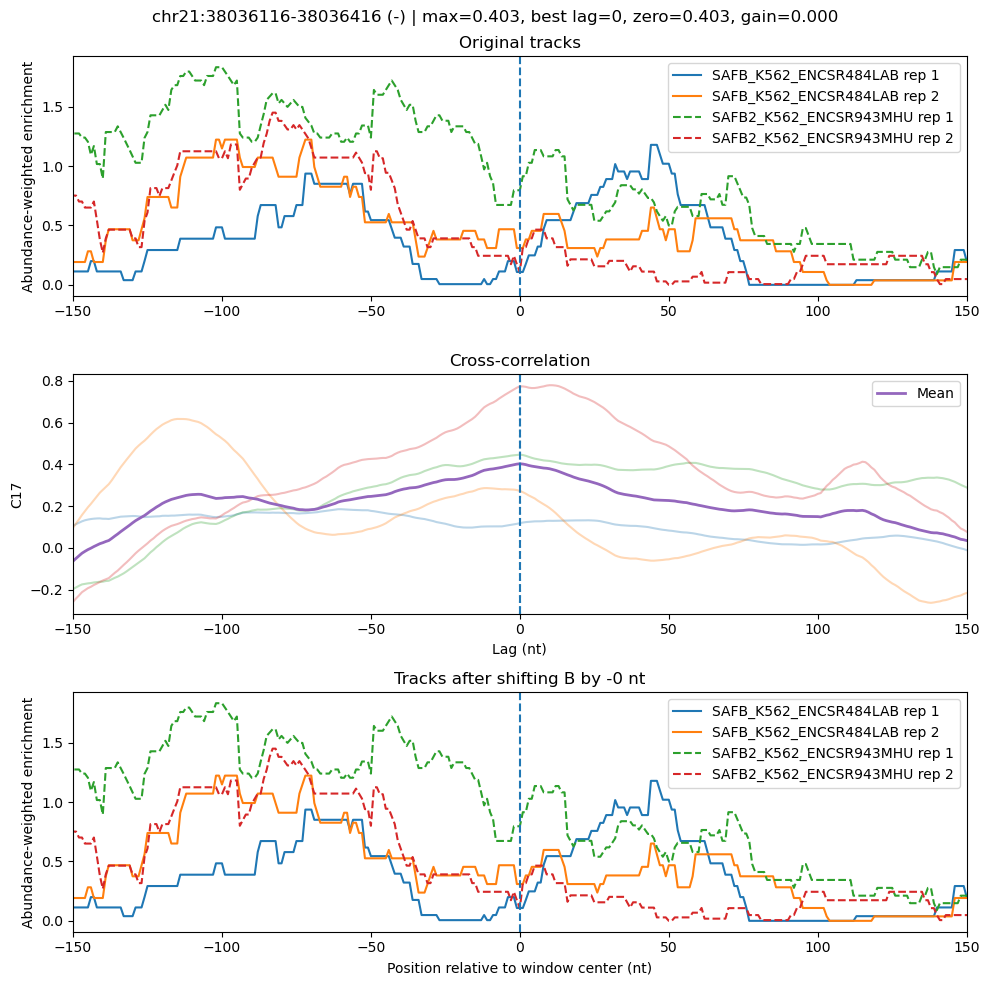

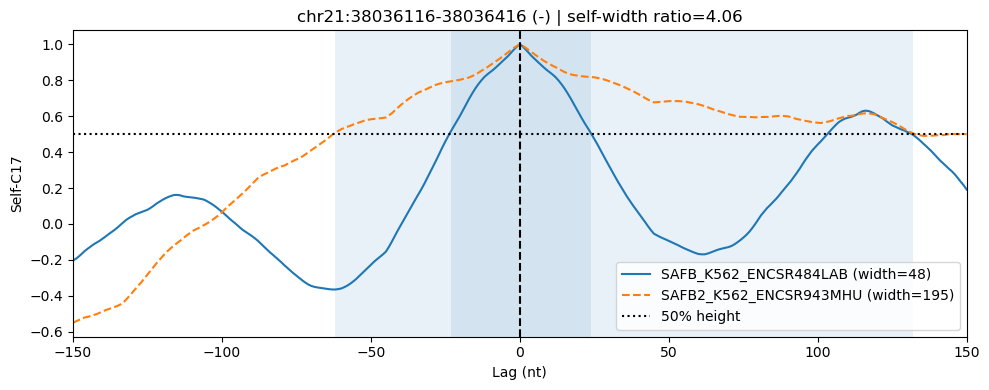

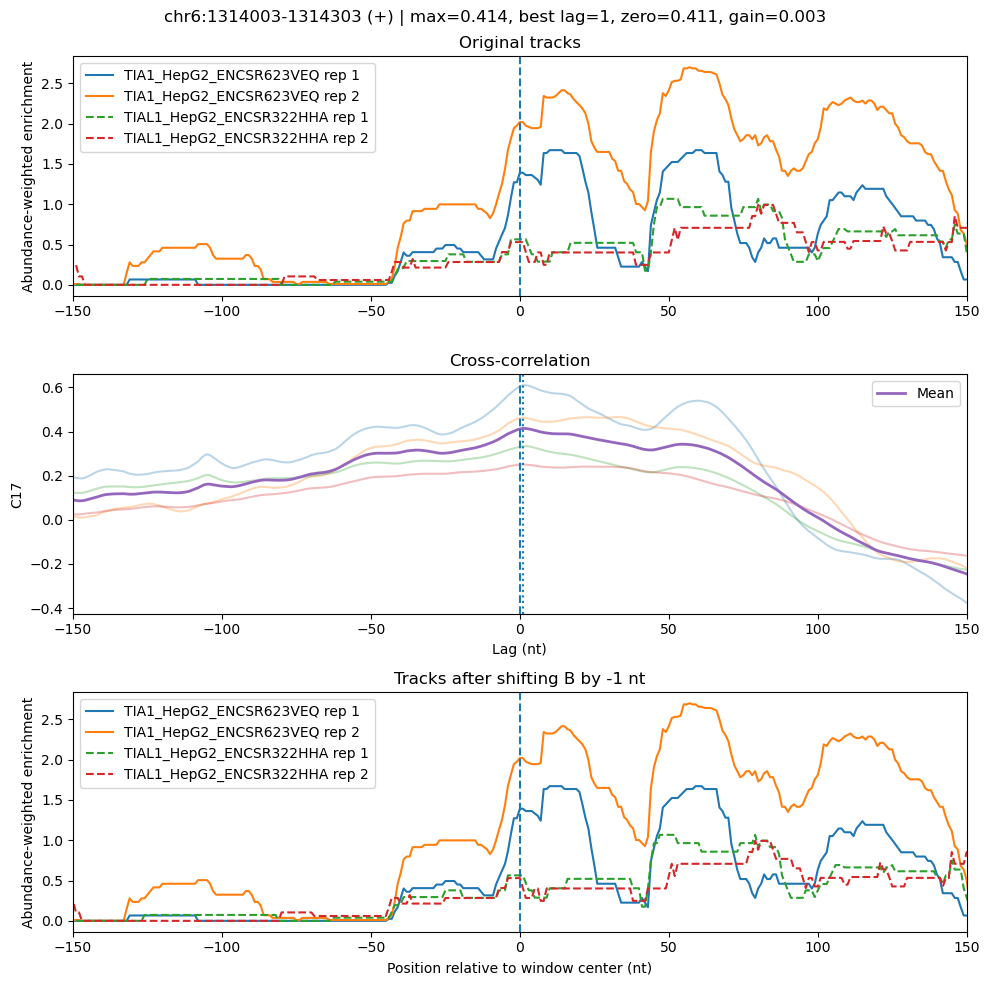

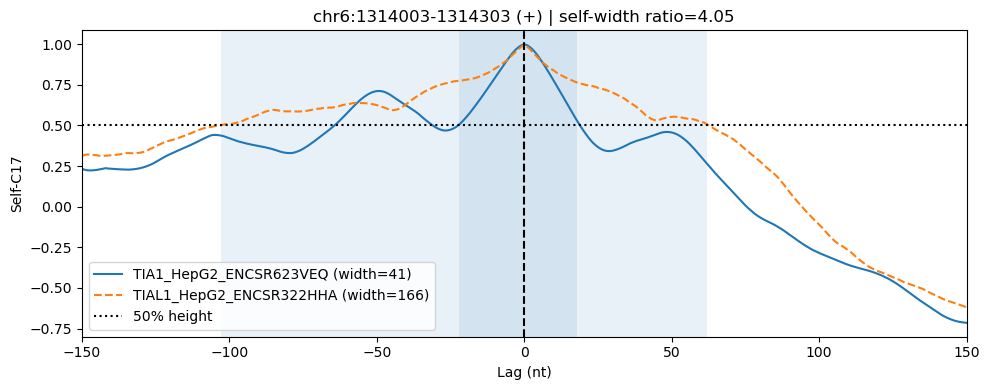

In [21]:
def get_mean_self_c17_curve(signal, max_lag=150):
    self_c17, lags = utils.C17(
        signal[None, :, :],
        signal[None, :, :],
        max_lag=max_lag
    )
    return mean_diagonal_c17(self_c17)[0], lags


def plot_self_c17_widths(
    row,
    comparison_data,
    fraction=0.5,
    max_lag=150
):
    comp = comparison_data[row["comparison_id"]]
    idx = int(row["window_idx"])

    curve_A, lags = get_mean_self_c17_curve(
        comp["signal_A"][idx],
        max_lag=max_lag
    )
    curve_B, _ = get_mean_self_c17_curve(
        comp["signal_B"][idx],
        max_lag=max_lag
    )

    plt.figure(figsize=(10, 4))

    plt.plot(
        lags,
        curve_A,
        label=(
            f"{row['experiment_A']} "
            f"(width={row['c17_self_width_A']:.0f})"
        )
    )
    plt.plot(
        lags,
        curve_B,
        linestyle="--",
        label=(
            f"{row['experiment_B']} "
            f"(width={row['c17_self_width_B']:.0f})"
        )
    )

    plt.axhline(
        fraction,
        color="black",
        linestyle=":",
        label=f"{fraction:.0%} height"
    )
    plt.axvline(0, color="black", linestyle="--")

    plt.axvspan(
        row["c17_self_left_A"],
        row["c17_self_right_A"],
        alpha=0.10
    )
    plt.axvspan(
        row["c17_self_left_B"],
        row["c17_self_right_B"],
        alpha=0.10
    )

    plt.xlim(-max_lag, max_lag)
    plt.xlabel("Lag (nt)")
    plt.ylabel("Self-C17")
    plt.title(
        f"{row['chrom']}:{row['start']}-{row['end']} "
        f"({row['strand']}) | "
        f"self-width ratio={row['c17_self_width_ratio']:.2f}"
    )
    plt.legend()
    plt.tight_layout()
    plt.show()


for _, row in width_candidates.head(5).iterrows():
    utils.plot_xcorr_window(row, comparison_data, "c17")
    plot_self_c17_widths(
        row,
        comparison_data,
        fraction=SELF_C17_FRACTION,
        max_lag=SELF_C17_MAX_LAG
    )